# Developed Markets Scorecard — **v4: hypothesis-driven research**
**US · Eurozone · UK · Switzerland · Japan** — rank five markets by expected *relative* return over 3–6 months

## What this notebook does differently
v1–v3 asked *"which indicators combine into a prediction?"*. v4 asks the prior question: **what economic force could move relative equity returns, and does the data contain information about it?**
Each pillar is built by a **nested experiment** — does adding a second variable to the first actually improve the forecast? — rather than by assuming more indicators is better.

**Target (explicit).** For market *i* at month *t* over horizon *h*:
$$R_{i,t,h}=\frac{P_{i,t+h}}{P_{i,t}}-1 \qquad Y_{i,t,h}=R_{i,t,h}-\overline{R}_{\text{peers},t,h}$$
We predict the **ranking of $Y$**, not the level of any index. A variable is only useful if it distinguishes *between* the five markets — which immediately rules some columns out (§1.4).

## Research design (locked before any v4 result)
| Stage | Work |
|---|---|
| **1 Data audit** | Verify every field, test whether the price proxy contaminates the signals, document unresolved definitions |
| **2 Hypotheses** | 5 economic hypotheses → 14 candidate features, each with a stated mechanism and an ex-ante direction |
| **3 Univariate tests** | Spearman rank IC, Newey-West t, discovery vs validation |
| **4 Incremental tests** | Nested comparison (does B add to A?) by paired ΔIC **and** Fama-MacBeth cross-sectional regression |
| **5 Scorecard** | One winner per pillar, chosen **on discovery only**, equal weight; validation touched once |
| **6 Backtest + calibration** | Long/short and long-only backtest, then a **50,000-combination sweep as a noise floor**: how good does the luckiest combination look? |

* **Discovery** 2007-01 → 2016-12 · **embargo** 2017-01 → 2017-06 (3M/6M forward returns overlap) · **validation** 2017-07 → 2026-04, frozen.
* **The sweep does not choose the scorecard.** It exists to answer "how much of any result could be luck?" If the hypothesis-driven scorecard sits inside the luck distribution, we say so.

## ⚠ Integrity accounting (read before the results)
* **The validation window has now been used twice** (v3, then v4). It is no longer pristine. A genuinely clean test needs forward data we do not have — i.e. paper trading.
* Specifications examined on this dataset: v1 = 1, v2 = 4, v3 = 43, v4 = ~24 hypothesis tests + a 50k calibration sweep. The sweep's max-statistic test corrects *within* itself; nothing can undo cumulative reuse across v1–v4.
* Two data definitions remain **unresolved** and are flagged at every stage: the supplied "price" file is not prices (§1.2), and the US EPS field is not the same kind of series as the other four (§1.3).

## 0. Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, itertools, time
from pathlib import Path
import statsmodels.api as sm
from scipy.stats import spearmanr, rankdata
from IPython.display import display, Markdown

pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 230
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})

ROOT = Path('..').resolve(); RAW, DATA = ROOT/'data'/'raw', ROOT/'data'
OUT = ROOT/'output'/'v4'; CH = OUT/'charts'
for p in (OUT, CH): p.mkdir(parents=True, exist_ok=True)

COUNTRIES = ['US', 'Eurozone', 'UK', 'Switzerland', 'Japan']
DISC = (pd.Period('2007-01', 'M'), pd.Period('2016-12', 'M'))
VAL_START = pd.Period('2017-07', 'M')
H_IC, SEED = 3, 7
ADJ_P_CAND, VAL_P = 0.10, 0.05
P_SWEEP, P_FINAL = 500, 3000
BETA_WIN, REG_WIN, MIN_HIST = 36, 24, 60

LEDGER = []      # experiment log, exported at the end
def log(eid, pillar, hypothesis, decision='pending', **kw):
    LEDGER.append(dict(id=eid, pillar=pillar, hypothesis=hypothesis, decision=decision, **kw))

## 1. Stage 1 — Data audit
### 1.1 Loading
Field mapping follows the assignment table. Cleaning: drop blank-date filler rows (UK 15, Switzerland 113), collapse to calendar month-end, sort ascending (Eurozone/Japan files are newest-first), de-duplicate.

In [2]:
SPEC = {
 'US':          dict(file='US_raw_data.xlsx',  eps='Monthly_EPS', pmi='NAPMPMI Index',  fci=('GSFCI Index', -1),   y2='USGGT02Y Index', oas='LF98OAS Index',  fx=None),
 'Eurozone':    dict(file='EUR_raw_data.xlsx', eps='BEst EPS',    pmi='MPMIEZMA Index', fci=('BFCIEU Index', +1),  y2='GDBR2 Index',    oas='LECPOAS Index', fx=('EURUSD BGN Curncy', 'direct')),
 'UK':          dict(file='UK_raw_data.xlsx',  eps='BEst EPS',    pmi='MPMIGBMA Index', fci=('GSGBFCI Index', -1), y2='GUKG2 Index',    oas='LC61OAS Index', fx=('GBPUSD BGN Curncy', 'direct')),
 'Switzerland': dict(file='CH_raw_data.xlsx',  eps='BEst EPS',    pmi='CH_PMI',         fci=('GSEAFCI Index', -1), y2='GSWISS02 Index', oas='LECPOAS Index', fx=('USDCHF Curncy', 'invert')),
 'Japan':       dict(file='JPY_raw_data.xlsx', eps='BEst EPS',    pmi='JPYPMI',         fci=('GSJPFCI Index', -1), y2='GJGB2 Index',    oas='LJC1OAS Index', fx=('USDJPY BGN Curncy', 'invert')),
}
PE_COL = 'BEst P/E Ratio'

def monthly(df):
    d = df.dropna(subset=['Date']).copy(); d['month'] = pd.to_datetime(d['Date']).dt.to_period('M')
    return d.sort_values('Date').drop_duplicates('month', keep='last').set_index('month')

def load_country(s):
    d = monthly(pd.read_excel(RAW/s['file']))
    o = pd.DataFrame({'pe': d[PE_COL], 'eps': d[s['eps']], 'pmi': d[s['pmi']], 'y2': d[s['y2']], 'oas': d[s['oas']]})
    o['fci'] = s['fci'][1] * d[s['fci'][0]]                              # oriented: higher = EASIER conditions
    o['fx'] = 1.0 if s['fx'] is None else (d[s['fx'][0]] if s['fx'][1] == 'direct' else 1.0 / d[s['fx'][0]])
    return o

frames = {c: load_country(SPEC[c]) for c in COUNTRIES}
START = max(frames[c].pe.first_valid_index() for c in COUNTRIES); AS_OF = min(frames[c].index.max() for c in COUNTRIES)
IDX = pd.period_range(START, AS_OF, freq='M')
PE, EPS, PMI, Y2, OAS, FCI, FX = [pd.DataFrame({c: frames[c][k] for c in COUNTRIES}).reindex(IDX) for k in ('pe', 'eps', 'pmi', 'y2', 'oas', 'fci', 'fx')]
us = monthly(pd.read_excel(RAW/'US_raw_data.xlsx'))
VIX, OIL, DXY = (us[k].reindex(IDX) for k in ('VIX Index', 'CO1 Comdty', 'DXY Index'))
assert all(d.notna().all().all() for d in (PE, EPS, PMI, Y2, OAS, FCI, FX))
print(f'Common window {START} -> {AS_OF} ({len(IDX)} months), no missing values in any market-specific series.')

PX = PE * EPS; PX_USD = PX * FX                                          # implied price (see 1.2)
R_LOC, R_USD = PX.pct_change(), PX_USD.pct_change()
fwd = {(b, h): (p.shift(-h) / p - 1) for b, p in (('local', PX), ('USD', PX_USD)) for h in (3, 6)}
REL = {k: v.sub(v.mean(axis=1), axis=0) for k, v in fwd.items()}          # Y = R_i - peer mean (the stated target)

Common window 2005-12 -> 2026-04 (245 months), no missing values in any market-specific series.


### 1.2 FINDING 1 — the supplied "price" file does not contain prices
`Price_data_all_countries.xlsx` is labelled as index levels but reproduces each market's **Forward P/E** series.

In [3]:
pf = pd.read_excel(RAW/'Price_data_all_countries.xlsx'); rows = []
for lab, (dc, vc) in {'US': ('US', 'SPX Index'), 'Eurozone': ('Eurozone ', 'MXEM Index'), 'UK': ('UK', 'MXGB Index'),
                      'Switzerland': ('Switzerland', 'MXCH Index'), 'Japan': ('Japan', 'MXJP Index')}.items():
    s = pf[[dc, vc]].dropna(); s.index = pd.to_datetime(s[dc]).dt.to_period('M'); s = s[vc]
    j = pd.concat([s.rename('file'), PE[lab].rename('pe')], axis=1).dropna()
    rows.append({'Market': lab, 'overlap months': len(j), 'corr with P/E': j.file.corr(j.pe), 'max abs diff': (j.file - j.pe).abs().max(), 'file range': f'{s.min():.1f} – {s.max():.1f}'})
display(pd.DataFrame(rows).set_index('Market').style.format({'corr with P/E': '{:.6f}', 'max abs diff': '{:.3f}'}))
print('Value ranges of 8-39 are P/E multiples, not index levels. Consequence: no true price or total-return index is available.')
print('DECISION (user-approved): implied price = Forward P/E x Forward EPS. This is a PROXY - price-return only, no dividends. Flagged on every output.')

,overlap months,corr with P/E,max abs diff,file range
Market,,,,
US,245,0.999994,0.055,10.5 – 24.8
Eurozone,245,1.000000,0.019,8.0 – 18.3
UK,245,1.000000,0.005,7.7 – 16.1
Switzerland,245,1.000000,0.010,10.4 – 20.4
Japan,245,0.999988,0.190,11.1 – 39.2


Value ranges of 8-39 are P/E multiples, not index levels. Consequence: no true price or total-return index is available.
DECISION (user-approved): implied price = Forward P/E x Forward EPS. This is a PROXY - price-return only, no dividends. Flagged on every output.


### 1.3 FINDING 2 — the US EPS field is not the same kind of series as the other four
The US workbook supplies `Monthly_EPS`; the other four supply `BEst EPS` (a forward consensus). The series behave differently.

In [4]:
g = EPS.pct_change()
au = pd.DataFrame({'monthly std': g.std(), 'autocorr(1)': g.apply(lambda x: x.autocorr()), 'share of months declining': (g < 0).mean(),
                   'field name': pd.Series({c: SPEC[c]['eps'] for c in COUNTRIES})})
display(au.style.format({'monthly std': '{:.4f}', 'autocorr(1)': '{:+.2f}', 'share of months declining': '{:.0%}'}))
print('US declines in ~20% of months vs 31-42% for the others -> consistent with a differently constructed (possibly trailing) series.')
print('UNRESOLVED: Bloomberg field definitions cannot be verified from this environment. Carried as a stated caveat; the US Overweight depends on it.')

,monthly std,autocorr(1),share of months declining,field name
US,0.0201,+0.65,20%,Monthly_EPS
Eurozone,0.0225,+0.73,32%,BEst EPS
UK,0.0290,+0.52,42%,BEst EPS
Switzerland,0.0199,+0.29,34%,BEst EPS
Japan,0.0463,+0.70,31%,BEst EPS


US declines in ~20% of months vs 31-42% for the others -> consistent with a differently constructed (possibly trailing) series.
UNRESOLVED: Bloomberg field definitions cannot be verified from this environment. Carried as a stated caveat; the US Overweight depends on it.


### 1.4 Which columns can rank markets at all?
A variable that takes the **same value for every market** on a given date carries zero cross-sectional information and cannot say which market will outperform — no matter how important it is for the asset class.

In [5]:
vixc = pd.DataFrame({'US': us['VIX Index'], 'Eurozone': monthly(pd.read_excel(RAW/'EUR_raw_data.xlsx'))['V2X Index'],
                     'UK': monthly(pd.read_excel(RAW/'UK_raw_data.xlsx'))['VIX Index'], 'Switzerland': monthly(pd.read_excel(RAW/'CH_raw_data.xlsx'))['VIX Index'],
                     'Japan': monthly(pd.read_excel(RAW/'JPY_raw_data.xlsx'))['VIX Index']}).reindex(IDX)
oilc = pd.DataFrame({c: monthly(pd.read_excel(RAW/SPEC[c]['file']))['CL1 Comdty (YEN)' if c == 'Japan' else 'CO1 Comdty'] for c in COUNTRIES}).reindex(IDX)
audit = pd.DataFrame([
    {'Column': 'PMI',            'Distinct values/month': PMI.apply(lambda r: r.nunique(), axis=1).mean(),  'Treatment': 'Country macro signal'},
    {'Column': 'EPS',            'Distinct values/month': EPS.apply(lambda r: r.nunique(), axis=1).mean(),  'Treatment': 'Country earnings signal (see 1.3)'},
    {'Column': 'Forward P/E',    'Distinct values/month': PE.apply(lambda r: r.nunique(), axis=1).mean(),   'Treatment': 'Country valuation signal'},
    {'Column': '2Y yield',       'Distinct values/month': Y2.apply(lambda r: r.nunique(), axis=1).mean(),   'Treatment': 'Country rate environment'},
    {'Column': 'Credit spread',  'Distinct values/month': OAS.apply(lambda r: r.nunique(), axis=1).mean(),  'Treatment': 'Country credit (CH duplicates EZ)'},
    {'Column': 'FCI',            'Distinct values/month': FCI.apply(lambda r: r.nunique(), axis=1).mean(),  'Treatment': 'Country financial conditions'},
    {'Column': 'FX',             'Distinct values/month': FX.apply(lambda r: r.nunique(), axis=1).mean(),   'Treatment': 'Country currency factor'},
    {'Column': 'VIX / V2X',      'Distinct values/month': vixc.apply(lambda r: r.nunique(), axis=1).mean(), 'Treatment': 'GLOBAL regime only - cannot rank'},
    {'Column': 'Oil',            'Distinct values/month': oilc.apply(lambda r: r.nunique(), axis=1).mean(), 'Treatment': 'GLOBAL shock - rank only via country sensitivity'},
    {'Column': 'DXY',            'Distinct values/month': 1.0,                                               'Treatment': 'GLOBAL - unused in v1-v3'},
]).set_index('Column')
display(audit.style.format({'Distinct values/month': '{:.1f}'}))
print(f'Oil in LOCAL currency does vary by market (FX differs): distinct values/month = {(OIL.values[:, None] / FX).apply(lambda r: r.nunique(), axis=1).mean():.1f}')
print('-> VIX/oil/DXY enter only as (a) regime conditioners or (b) country factor betas / local-currency cost. Never as raw ranking signals.')

,Distinct values/month,Treatment
Column,,
PMI,4.9,Country macro signal
EPS,5.0,Country earnings signal (see 1.3)
Forward P/E,5.0,Country valuation signal
2Y yield,5.0,Country rate environment
Credit spread,4.0,Country credit (CH duplicates EZ)
FCI,5.0,Country financial conditions
FX,5.0,Country currency factor
VIX / V2X,3.0,GLOBAL regime only - cannot rank
Oil,2.0,GLOBAL shock - rank only via country sensitivity


Oil in LOCAL currency does vary by market (FX differs): distinct values/month = 5.0
-> VIX/oil/DXY enter only as (a) regime conditioners or (b) country factor betas / local-currency cost. Never as raw ranking signals.


### 1.5 Does the price proxy contaminate the signals?
Implied price $P_t = (P/E)_t \times EPS_t$, so **both the valuation and the earnings signal share an observation with the return's denominator**.
Noise in $(P/E)_t$ raises $P_t$ and depresses $R_{t,t+h}$ → a spurious **positive** IC for the inverted-P/E signal.
Noise in $EPS_t$ raises the revision signal *and* $P_t$ → a spurious **negative** IC for earnings revisions.
**Test:** lag the signal so it no longer shares the observation that sets $P_t$. If the IC is mechanical, it collapses.

In [6]:
def sp_ic(sig, f, lo, hi):
    out = []
    for t in sig.index:
        if not (lo <= t <= hi): continue
        s, y = sig.loc[t], f.loc[t]
        if s.notna().all() and y.notna().all() and s.nunique() > 1: out.append(spearmanr(s, y).statistic)
    return (np.mean(out) if out else np.nan), len(out)
zexp = lambda x, m=MIN_HIST: (x - x.expanding(m).mean()) / x.expanding(m).std()
V_W = (VAL_START, AS_OF)
rows = []
for lag in (0, 1, 3):
    rows.append({'Lag (months)': lag, 'Signal': 'Valuation: -z(P/E)', 'Discovery IC': sp_ic(-zexp(PE).shift(lag), fwd[('USD', 3)], *DISC)[0], 'Validation IC': sp_ic(-zexp(PE).shift(lag), fwd[('USD', 3)], *V_W)[0]})
    s2 = (EPS / EPS.shift(6) - 1).shift(lag)
    rows.append({'Lag (months)': lag, 'Signal': 'Micro: EPS revision 6M', 'Discovery IC': sp_ic(s2, fwd[('USD', 3)], *DISC)[0], 'Validation IC': sp_ic(s2, fwd[('USD', 3)], *V_W)[0]})
display(pd.DataFrame(rows).pivot(index='Signal', columns='Lag (months)', values=['Discovery IC', 'Validation IC']).style.format('{:+.3f}'))
print('RESULT: ICs do not collapse when lagged - they are flat or slightly stronger. Mechanical contamination is NOT supported.')
print('  -> valuation reversing sign between the two windows is a genuine regime change, not an artefact;')
print('  -> EPS revision clears the bar DESPITE a mechanical headwind working against it.')
log('D01', 'Audit', 'Supplied price file contains P/E, not prices', 'CONFIRMED - use implied price proxy')
log('D02', 'Audit', 'US EPS field differs in kind from the other four', 'CONFIRMED - flagged, kept (user decision)')
log('D03', 'Audit', 'Price proxy mechanically contaminates valuation / EPS signals', 'REJECTED - IC survives 1M and 3M lags')

RESULT: ICs do not collapse when lagged - they are flat or slightly stronger. Mechanical contamination is NOT supported.
  -> valuation reversing sign between the two windows is a genuine regime change, not an artefact;
  -> EPS revision clears the bar DESPITE a mechanical headwind working against it.


## 2. Stage 2 — Hypotheses and the feature library
Five economic hypotheses. Every feature states its **mechanism**, its **transmission channel to equities**, its **expected horizon**, and its **ex-ante direction**. Directions are fixed here and never flipped afterwards; no inverse copies are created for ambiguous-sign variables.

| ID | Pillar | Feature | Mechanism → equity channel | Direction |
|---|---|---|---|---|
| M01 | Macro | PMI 3M change (lag 1M) | Activity momentum → revenue/earnings expectations | higher = better |
| M02 | Macro | Credit spread 3M tightening | Cheaper financing + rising risk appetite → multiple expansion | tightening = better |
| M03 | Macro | FCI 6M easing | Broadest financing-conditions measure; *leads* activity (PMI is coincident) | easing = better |
| MI01 | Micro | EPS growth 12M | Realised earnings power | higher = better |
| MI02 | Micro | EPS revision 6M | Expectation changes; upgrades persist (revision effect) | higher = better |
| MI03 | Micro | EPS revision 3M | Same mechanism, faster window | higher = better |
| V01 | Valuation | P/E z vs own 60M+ history, inverted | Multiple mean-reversion | cheap = better |
| V02 | Valuation | Earnings-yield spread (E/P − 2Y), z | Equity risk premium vs the local risk-free alternative | higher ERP = better |
| V03 | Valuation | Relative P/E vs peer average, inverted | Cross-market relative value | cheap = better |
| T01 | Technical | Momentum 6-1M | Trend persistence, skip latest month (reversal) | higher = better |
| T02 | Technical | Momentum 12-1M | Longer trend window | higher = better |
| T03 | Technical | Risk-adjusted momentum 12-1M | Trend per unit of volatility | higher = better |
| F01 | Factor | Oil cost in **local currency**, 6M change, inverted | Energy import cost in domestic terms — varies by market through FX, no estimation needed | rising cost = worse |
| F02 | Factor | Oil beta (36M) × oil 3M change | Country sensitivity to the global oil shock, estimated from past returns | benefits = better |
| F03 | Factor | Dollar beta (36M) × DXY 3M change | Country sensitivity to the dollar cycle | benefits = better |
| F04 | Factor | VIX beta (36M), inverted | Low-beta / defensive exposure to global risk-off | lower beta = better |

**Hypotheses under test**
* **H1** Economic acceleration predicts outperformance — and does each extra macro variable *add* to the one before (M01 → +M02 → +M03)?
* **H2** Expectation changes (MI02) beat realised growth (MI01), and combining adds information.
* **H3** *(your GARP idea)* Cheap markets with improving earnings outperform — tested three ways: additive, conjunction ("good on both"), and conditional ("upgrades, but only among the cheap half").
* **H4** Global shocks hit markets differently; country sensitivity turns a global variable into a ranking signal.
* **H5** Relative momentum persists.

In [7]:
def chg(x, L): return x - x.shift(L)
def pct(x, L): return x / x.shift(L) - 1
def own(d, m=BETA_WIN): return d / d.expanding(m).std()
def cs_z(df):
    ok = df.notna().all(axis=1)
    return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1, ddof=1), axis=0).where(ok)

def roll_beta(fac_ret, win=BETA_WIN):
    """rolling beta of each market's local return on a common factor return (past data only)"""
    out = pd.DataFrame(index=IDX, columns=COUNTRIES, dtype=float)
    f = fac_ret.reindex(IDX)
    for c in COUNTRIES:
        cov = R_LOC[c].rolling(win).cov(f); var = f.rolling(win).var()
        out[c] = cov / var
    return out

PM = PMI.shift(1)                                                   # PMI is published ~1st business day of the NEXT month
oil_ret, dxy_ret, vix_chg = OIL.pct_change(), DXY.pct_change(), VIX.diff()
B_OIL, B_DXY, B_VIX = roll_beta(oil_ret), roll_beta(dxy_ret), roll_beta(vix_chg)
OIL_LOCAL = pd.DataFrame({c: OIL / FX[c] for c in COUNTRIES})       # oil priced in each market's own currency

FEAT = {
 'M01 PMI 3M change':                  chg(PM, 3),
 'M02 Credit spread 3M tightening':   -own(chg(OAS, 3)),
 'M03 FCI 6M easing':                  own(chg(FCI, 6)),
 'MI01 EPS growth 12M':                pct(EPS, 12),
 'MI02 EPS revision 6M':               pct(EPS, 6),
 'MI03 EPS revision 3M':               pct(EPS, 3),
 'V01 P/E z own history (inv)':       -zexp(PE),
 'V02 Earnings yield spread (E/P-2Y)': zexp(100 / PE - Y2),
 'V03 Relative P/E vs peers (inv)':   -zexp(PE.div(PE.mean(axis=1), axis=0)),
 'T01 Momentum 6-1M':                  PX.shift(1) / PX.shift(7) - 1,
 'T02 Momentum 12-1M':                 PX.shift(1) / PX.shift(13) - 1,
 'T03 Risk-adj momentum 12-1M':       (PX.shift(1) / PX.shift(13) - 1) / R_LOC.rolling(12).std(),
 'F01 Local-currency oil cost (inv)': -pct(OIL_LOCAL, 6),
 'F02 Oil beta x oil 3M move':         B_OIL.mul(pct(OIL, 3), axis=0),
 'F03 Dollar beta x DXY 3M move':      B_DXY.mul(pct(DXY, 3), axis=0),
 'F04 VIX beta (inv, defensive)':     -B_VIX,
}
Z = {k: cs_z(v.reindex(IDX)) for k, v in FEAT.items()}
PILLAR = {k: ('Macro' if k[0] == 'M' and k[1] != 'I' else 'Micro' if k.startswith('MI') else 'Valuation' if k[0] == 'V' else 'Technical' if k[0] == 'T' else 'Factor') for k in FEAT}
print(f'{len(FEAT)} features built.  First month with all features valid: {max(z.dropna().index.min() for z in Z.values())}')

16 features built.  First month with all features valid: 2010-11


## 3. Stage 3/4 — the testing laboratory
* **Spearman rank IC** per month, cross-sectional across the five markets; Newey-West t (lags = horizon) for the overlapping-return problem.
* **Fama-MacBeth**: a cross-sectional regression of relative return $Y_{i,t,h}$ on signal z-scores each month, then a Newey-West t-stat on the time series of slopes. This is the right tool for "does B add information *after controlling for* A" with a 5-market panel.
* **Paired ΔIC**: monthly IC of model(A+B) minus monthly IC of model(A); NW t-stat on the mean difference. Paired, so it tests the *improvement* directly.
* **Block permutation** p-value: country labels shuffled in 3-month blocks (preserves persistence and return overlap), one-sided because directions were fixed ex ante.

In [8]:
def ic_series(sig, f):
    out = {}
    for t in sig.index:
        s, y = sig.loc[t], f.loc[t]
        if s.notna().all() and y.notna().all() and s.nunique() > 1: out[t] = spearmanr(s, y).statistic
    return pd.Series(out)

def nw_t(x, lags=H_IC):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) < 12: return np.nan
    return float(sm.OLS(x, np.ones(len(x))).fit(cov_type='HAC', cov_kwds={'maxlags': lags}).tvalues[0])

def win(s, w): return s[(s.index >= w[0]) & (s.index <= w[1])]
D_W, V_W = DISC, (VAL_START, AS_OF)

def perm_p(sig, f, w, h=H_IC, n=2000, seed=SEED):
    ic = win(ic_series(sig, f), w)
    if len(ic) < 12: return np.nan
    S = sig.loc[ic.index].to_numpy(float); F = f.loc[ic.index].to_numpy(float)
    Sr = np.apply_along_axis(rankdata, 1, S) - 3.0; Fr = np.apply_along_axis(rankdata, 1, F) - 3.0
    den = np.sqrt((Sr**2).sum(1) * (Fr**2).sum(1)); den[den == 0] = np.nan
    obs = np.nanmean((Sr * Fr).sum(1) / den)
    T = len(ic); blk = np.arange(T) // h; B = blk.max() + 1
    rng = np.random.default_rng(seed); cnt = 0
    for _ in range(n):
        idx = np.argsort(rng.random((B, 5)), axis=1)[blk]
        Sp = np.take_along_axis(Sr, idx, axis=1)
        if np.nanmean((Sp * Fr).sum(1) / den) >= obs: cnt += 1
    return (cnt + 1) / (n + 1)

def composite(names, how='mean'):
    zs = [Z[n] for n in names]
    if how == 'mean': return sum(zs) / len(zs)
    if how == 'min':  return pd.concat(zs).groupby(level=0).min().reindex(zs[0].index)[COUNTRIES]

def fama_macbeth(sigs, f, w, h=H_IC):
    """cross-sectional regression each month -> NW t on the slope time series"""
    coefs = {}
    for t in f.index:
        if not (w[0] <= t <= w[1]): continue
        y = REL[('USD', h)].loc[t] if f is fwd[('USD', h)] else f.loc[t] - f.loc[t].mean()
        X = pd.DataFrame({n: Z[n].loc[t] for n in sigs})
        if y.isna().any() or X.isna().any().any(): continue
        m = sm.OLS(y.values, sm.add_constant(X.values)).fit()
        coefs[t] = m.params[1:]
    if not coefs: return pd.DataFrame()
    C = pd.DataFrame(coefs, index=sigs).T
    return pd.DataFrame({'FM slope (%/month per 1 z)': C.mean() * 100, 'FM NW t': [nw_t(C[c].values, h) for c in C]})

def evaluate(name, sig, note=''):
    r = {'Model': name}
    for lab, w in (('disc', D_W), ('val', V_W)):
        for bas in ('USD', 'local'):
            ic = win(ic_series(sig, fwd[(bas, 3)]), w)
            r[f'{lab} IC {bas}'] = ic.mean(); r[f'{lab} t {bas}'] = nw_t(ic.values)
    r['disc p(perm)'] = perm_p(sig, fwd[('USD', 3)], D_W)
    r['val p(perm)'] = perm_p(sig, fwd[('USD', 3)], V_W)
    r['note'] = note
    return r

def delta_ic(base_names, add_names, w, bas='USD'):
    """paired improvement test: does adding `add_names` to `base_names` raise the monthly IC?"""
    a = win(ic_series(composite(base_names), fwd[(bas, 3)]), w)
    b = win(ic_series(composite(base_names + add_names), fwd[(bas, 3)]), w)
    j = pd.concat([a.rename('base'), b.rename('plus')], axis=1).dropna()
    d = j.plus - j.base
    return {'IC base': j.base.mean(), 'IC with addition': j.plus.mean(), 'Delta IC': d.mean(), 'Delta NW t': nw_t(d.values), 'months': len(d)}

### 3.1 Univariate screen — every feature, both windows
Nothing is selected here; this is the evidence base for the nested tests.

In [9]:
UNI = pd.DataFrame([evaluate(k, Z[k]) for k in FEAT]).set_index('Model')
UNI.insert(0, 'pillar', pd.Series(PILLAR))
fmt = {c: '{:+.3f}' for c in UNI.columns if ' IC ' in c} | {c: '{:+.2f}' for c in UNI.columns if ' t ' in c} | {c: '{:.3f}' for c in UNI.columns if 'perm' in c}
display(UNI.sort_values('disc IC USD', ascending=False).drop(columns='note').style.format(fmt))
sign_stable = UNI[(UNI['disc IC USD'] > 0) & (UNI['val IC USD'] > 0)].index.tolist()
print(f'Features positive in BOTH windows ({len(sign_stable)}/{len(FEAT)}): ' + ', '.join(sign_stable))

,pillar,disc IC USD,disc t USD,disc IC local,disc t local,val IC USD,val t USD,val IC local,val t local,disc p(perm),val p(perm)
Model,,,,,,,,,,,
V03 Relative P/E vs peers (inv),Valuation,+0.168,+1.73,+0.076,+0.71,-0.108,-1.57,-0.050,-0.65,0.022,0.959
V01 P/E z own history (inv),Valuation,+0.141,+2.03,+0.077,+0.84,-0.126,-1.96,-0.017,-0.22,0.034,0.975
MI01 EPS growth 12M,Micro,+0.122,+1.61,+0.034,+0.58,+0.046,+0.59,+0.113,+1.73,0.027,0.239
MI02 EPS revision 6M,Micro,+0.117,+1.67,+0.087,+1.55,+0.131,+1.70,+0.145,+2.10,0.026,0.024
M03 FCI 6M easing,Macro,+0.079,+1.08,+0.100,+1.56,+0.127,+1.74,+0.095,+1.30,0.130,0.020
V02 Earnings yield spread (E/P-2Y),Valuation,+0.078,+0.96,+0.172,+1.83,-0.093,-1.52,-0.073,-0.98,0.163,0.915
T02 Momentum 12-1M,Technical,+0.055,+1.06,+0.044,+0.79,+0.103,+1.38,+0.128,+1.90,0.191,0.062
F01 Local-currency oil cost (inv),Factor,+0.048,+0.79,-0.028,-0.41,-0.121,-1.66,-0.117,-1.75,0.188,0.967
T03 Risk-adj momentum 12-1M,Technical,+0.036,+0.71,+0.051,+0.95,+0.129,+1.83,+0.168,+2.90,0.285,0.023


Features positive in BOTH windows (6/16): M03 FCI 6M easing, MI01 EPS growth 12M, MI02 EPS revision 6M, T02 Momentum 12-1M, T03 Risk-adj momentum 12-1M, F04 VIX beta (inv, defensive)


## 4. Stage 4 — Nested experiments
For each pillar: does the second variable add to the first, and the third to the pair? Judged by **paired ΔIC on discovery** and by the **Fama-MacBeth slope** of the added variable after controlling for the incumbent.
A variable that does not add is dropped. No attachment to any indicator.

### H1 — Economic acceleration (Macro)

In [10]:
MAC = {'M_A  PMI alone': ['M01 PMI 3M change'],
       'M_B  PMI + credit': ['M01 PMI 3M change', 'M02 Credit spread 3M tightening'],
       'M_C  PMI + credit + FCI': ['M01 PMI 3M change', 'M02 Credit spread 3M tightening', 'M03 FCI 6M easing'],
       'M_D  FCI alone': ['M03 FCI 6M easing'],
       'M_E  credit + FCI (drop PMI)': ['M02 Credit spread 3M tightening', 'M03 FCI 6M easing']}
display(pd.DataFrame([evaluate(k, composite(v)) for k, v in MAC.items()]).set_index('Model').drop(columns='note').style.format(fmt))
print('Incremental tests on DISCOVERY (paired delta-IC):')
inc = pd.DataFrame([{'Step': 'A -> B  (add credit to PMI)', **delta_ic(MAC['M_A  PMI alone'], ['M02 Credit spread 3M tightening'], D_W)},
                    {'Step': 'B -> C  (add FCI to PMI+credit)', **delta_ic(MAC['M_B  PMI + credit'], ['M03 FCI 6M easing'], D_W)},
                    {'Step': 'D -> E  (add credit to FCI)', **delta_ic(MAC['M_D  FCI alone'], ['M02 Credit spread 3M tightening'], D_W)}]).set_index('Step')
display(inc.style.format({'IC base': '{:+.3f}', 'IC with addition': '{:+.3f}', 'Delta IC': '{:+.3f}', 'Delta NW t': '{:+.2f}'}))
print('Fama-MacBeth, all three macro variables jointly (discovery, relative USD 3M return):')
display(fama_macbeth(['M01 PMI 3M change', 'M02 Credit spread 3M tightening', 'M03 FCI 6M easing'], fwd[('USD', 3)], D_W).style.format({'FM slope (%/month per 1 z)': '{:+.2f}', 'FM NW t': '{:+.2f}'}))

,disc IC USD,disc t USD,disc IC local,disc t local,val IC USD,val t USD,val IC local,val t local,disc p(perm),val p(perm)
Model,,,,,,,,,,
M_A PMI alone,-0.045,-0.81,-0.039,-0.68,-0.038,-0.65,+0.014,+0.22,0.806,0.739
M_B PMI + credit,-0.134,-2.47,-0.088,-1.49,-0.022,-0.40,-0.031,-0.52,0.985,0.655
M_C PMI + credit + FCI,-0.084,-1.32,-0.072,-1.16,+0.021,+0.38,-0.004,-0.06,0.907,0.354
M_D FCI alone,+0.079,+1.08,+0.100,+1.56,+0.127,+1.74,+0.095,+1.30,0.130,0.020
M_E credit + FCI (drop PMI),-0.029,-0.41,-0.004,-0.07,+0.048,+0.76,+0.012,+0.19,0.682,0.205


Incremental tests on DISCOVERY (paired delta-IC):


,IC base,IC with addition,Delta IC,Delta NW t,months
Step,,,,,
A -> B (add credit to PMI),-0.105,-0.134,-0.029,-0.53,95
B -> C (add FCI to PMI+credit),-0.126,-0.084,+0.043,+0.99,92
D -> E (add credit to FCI),+0.079,-0.029,-0.109,-1.78,92


Fama-MacBeth, all three macro variables jointly (discovery, relative USD 3M return):


,FM slope (%/month per 1 z),FM NW t
M01 PMI 3M change,-0.91,-0.79
M02 Credit spread 3M tightening,+0.44,+0.41
M03 FCI 6M easing,+1.53,+1.77


### H2 — Expectations vs realised earnings (Micro)

In [11]:
MIC = {'MI_A  EPS growth 12M': ['MI01 EPS growth 12M'], 'MI_B  EPS revision 6M': ['MI02 EPS revision 6M'],
       'MI_C  growth + revision': ['MI01 EPS growth 12M', 'MI02 EPS revision 6M'], 'MI_D  revision 6M + 3M': ['MI02 EPS revision 6M', 'MI03 EPS revision 3M']}
display(pd.DataFrame([evaluate(k, composite(v)) for k, v in MIC.items()]).set_index('Model').drop(columns='note').style.format(fmt))
display(pd.DataFrame([{'Step': 'growth -> + revision', **delta_ic(['MI01 EPS growth 12M'], ['MI02 EPS revision 6M'], D_W)},
                      {'Step': 'revision -> + growth', **delta_ic(['MI02 EPS revision 6M'], ['MI01 EPS growth 12M'], D_W)}]).set_index('Step').style.format({'IC base': '{:+.3f}', 'IC with addition': '{:+.3f}', 'Delta IC': '{:+.3f}', 'Delta NW t': '{:+.2f}'}))
display(fama_macbeth(['MI01 EPS growth 12M', 'MI02 EPS revision 6M'], fwd[('USD', 3)], D_W).style.format({'FM slope (%/month per 1 z)': '{:+.2f}', 'FM NW t': '{:+.2f}'}))

,disc IC USD,disc t USD,disc IC local,disc t local,val IC USD,val t USD,val IC local,val t local,disc p(perm),val p(perm)
Model,,,,,,,,,,
MI_A EPS growth 12M,+0.122,+1.61,+0.034,+0.58,+0.046,+0.59,+0.113,+1.73,0.027,0.239
MI_B EPS revision 6M,+0.117,+1.67,+0.087,+1.55,+0.131,+1.70,+0.145,+2.10,0.026,0.024
MI_C growth + revision,+0.129,+1.71,+0.074,+1.32,+0.097,+1.24,+0.146,+2.26,0.018,0.065
MI_D revision 6M + 3M,+0.049,+0.75,+0.045,+0.80,+0.128,+1.80,+0.164,+2.42,0.209,0.023


,IC base,IC with addition,Delta IC,Delta NW t,months
Step,,,,,
growth -> + revision,+0.122,+0.129,+0.007,+0.31,120
revision -> + growth,+0.117,+0.129,+0.012,+0.52,120


,FM slope (%/month per 1 z),FM NW t
MI01 EPS growth 12M,-1.09,-0.82
MI02 EPS revision 6M,+1.58,+1.37


### H3 — *Cheap markets with improving earnings* (your GARP hypothesis), three ways
The three forms are **different hypotheses**, not three versions of one:
* **Additive** — valuation gets an equal *vote*: a very cheap market can outrank an upgrading one.
* **Conjunction** `min(z)` — a market must be good on **both**; being cheap cannot compensate for downgrades.
* **Conditional filter** — rank on revisions, but only among markets cheaper than median; the rest are set to neutral.

In [12]:
cheap = Z['V03 Relative P/E vs peers (inv)']; eps6 = Z['MI02 EPS revision 6M']
garp_cond = eps6.where(cheap > 0, 0.0)
GARP = {'G_A  EPS revision alone': eps6, 'G_B  additive (EPS + cheap)': composite(['MI02 EPS revision 6M', 'V03 Relative P/E vs peers (inv)']),
        'G_C  conjunction min(EPS, cheap)': composite(['MI02 EPS revision 6M', 'V03 Relative P/E vs peers (inv)'], how='min'),
        'G_D  EPS within the cheap half': garp_cond}
display(pd.DataFrame([evaluate(k, v) for k, v in GARP.items()]).set_index('Model').drop(columns='note').style.format(fmt))

,disc IC USD,disc t USD,disc IC local,disc t local,val IC USD,val t USD,val IC local,val t local,disc p(perm),val p(perm)
Model,,,,,,,,,,
G_A EPS revision alone,+0.117,+1.67,+0.087,+1.55,+0.131,+1.70,+0.145,+2.10,0.026,0.024
G_B additive (EPS + cheap),+0.162,+1.68,+0.126,+1.55,-0.042,-0.67,+0.031,+0.44,0.023,0.761
"G_C conjunction min(EPS, cheap)",+0.080,+1.08,+0.047,+0.72,-0.043,-0.71,+0.015,+0.22,0.089,0.758
G_D EPS within the cheap half,-0.021,-0.21,+0.032,+0.42,+0.055,+0.75,+0.065,+0.94,0.606,0.188


### Valuation and Technical pillars

In [13]:
VAL = {'V_A  P/E own history': ['V01 P/E z own history (inv)'], 'V_B  earnings-yield spread': ['V02 Earnings yield spread (E/P-2Y)'],
       'V_C  relative P/E': ['V03 Relative P/E vs peers (inv)'], 'V_D  own history + ERP': ['V01 P/E z own history (inv)', 'V02 Earnings yield spread (E/P-2Y)']}
TEC = {'T_A  momentum 6-1M': ['T01 Momentum 6-1M'], 'T_B  momentum 12-1M': ['T02 Momentum 12-1M'],
       'T_C  risk-adjusted 12-1M': ['T03 Risk-adj momentum 12-1M'], 'T_D  6-1M + 12-1M': ['T01 Momentum 6-1M', 'T02 Momentum 12-1M']}
display(pd.DataFrame([evaluate(k, composite(v)) for k, v in {**VAL, **TEC}.items()]).set_index('Model').drop(columns='note').style.format(fmt))

,disc IC USD,disc t USD,disc IC local,disc t local,val IC USD,val t USD,val IC local,val t local,disc p(perm),val p(perm)
Model,,,,,,,,,,
V_A P/E own history,+0.141,+2.03,+0.077,+0.84,-0.126,-1.96,-0.017,-0.22,0.034,0.975
V_B earnings-yield spread,+0.078,+0.96,+0.172,+1.83,-0.093,-1.52,-0.073,-0.98,0.163,0.915
V_C relative P/E,+0.168,+1.73,+0.076,+0.71,-0.108,-1.57,-0.050,-0.65,0.022,0.959
V_D own history + ERP,+0.107,+1.48,+0.103,+1.24,-0.150,-2.54,-0.073,-0.96,0.091,0.992
T_A momentum 6-1M,-0.017,-0.27,+0.003,+0.05,+0.059,+0.85,+0.085,+1.44,0.622,0.181
T_B momentum 12-1M,+0.055,+1.06,+0.044,+0.79,+0.103,+1.38,+0.128,+1.90,0.191,0.062
T_C risk-adjusted 12-1M,+0.036,+0.71,+0.051,+0.95,+0.129,+1.83,+0.168,+2.90,0.285,0.023
T_D 6-1M + 12-1M,+0.032,+0.58,+0.053,+0.93,+0.117,+1.65,+0.131,+1.93,0.308,0.040


### H4 — Do global shocks hit the five markets differently?
VIX, oil and the dollar are identical across markets, so they can only rank through **country sensitivity**: estimated betas, or — with no estimation at all — the oil price expressed in each market's own currency.

In [14]:
FAC = {'F_A  local-currency oil cost': ['F01 Local-currency oil cost (inv)'], 'F_B  oil beta x oil move': ['F02 Oil beta x oil 3M move'],
       'F_C  dollar beta x DXY move': ['F03 Dollar beta x DXY 3M move'], 'F_D  low VIX beta (defensive)': ['F04 VIX beta (inv, defensive)']}
display(pd.DataFrame([evaluate(k, composite(v)) for k, v in FAC.items()]).set_index('Model').drop(columns='note').style.format(fmt))
print('Average 36M betas by market (how different ARE the sensitivities?)')
display(pd.DataFrame({'oil beta': B_OIL.mean(), 'dollar beta': B_DXY.mean(), 'VIX beta': B_VIX.mean()}).style.format('{:+.3f}'))

,disc IC USD,disc t USD,disc IC local,disc t local,val IC USD,val t USD,val IC local,val t local,disc p(perm),val p(perm)
Model,,,,,,,,,,
F_A local-currency oil cost,+0.048,+0.79,-0.028,-0.41,-0.121,-1.66,-0.117,-1.75,0.188,0.967
F_B oil beta x oil move,-0.022,-0.35,-0.086,-1.42,-0.041,-0.77,-0.066,-1.20,0.646,0.750
F_C dollar beta x DXY move,-0.079,-1.34,-0.134,-1.97,+0.018,+0.38,-0.031,-0.56,0.920,0.364
F_D low VIX beta (defensive),+0.006,+0.10,+0.002,+0.03,+0.132,+2.10,+0.072,+1.00,0.474,0.017


Average 36M betas by market (how different ARE the sensitivities?)


,oil beta,dollar beta,VIX beta
US,+0.202,-0.925,-0.007
Eurozone,+0.196,-0.673,-0.006
UK,+0.183,-0.503,-0.005
Switzerland,+0.100,-0.314,-0.004
Japan,+0.186,-0.377,-0.005


## 5. Stage 5 — Build the scorecard
**Selection rule (fixed in advance): per pillar take the model with the highest DISCOVERY IC (USD, 3M). Validation is not consulted.**
The assignment requires at least one Macro, Micro, Valuation and Technical signal, so all four pillars are carried even where the evidence is weak — their weakness is reported rather than hidden.

In [15]:
GROUPS = {'Macro': MAC, 'Micro': MIC, 'Valuation': VAL, 'Technical': TEC, 'Factor': FAC}
sel_rows, WIN = [], {}
for pil, grp in GROUPS.items():
    cand = {k: composite(v) for k, v in grp.items()}
    d = {k: win(ic_series(s, fwd[('USD', 3)]), D_W).mean() for k, s in cand.items()}
    best = max(d, key=d.get); WIN[pil] = (best, grp[best], cand[best])
    sel_rows.append({'Pillar': pil, 'Winner (discovery)': best, 'Features': ' + '.join(x.split(' ', 1)[0] for x in grp[best]), 'Discovery IC': d[best],
                     'Runner-up': sorted(d, key=d.get, reverse=True)[1], 'Runner-up IC': sorted(d.values(), reverse=True)[1]})
display(pd.DataFrame(sel_rows).set_index('Pillar').style.format({'Discovery IC': '{:+.3f}', 'Runner-up IC': '{:+.3f}'}))

CORE4 = ['Macro', 'Micro', 'Valuation', 'Technical']
SC = {'v4 scorecard (4 required pillars)': sum(WIN[p][2] for p in CORE4) / 4,
      'v4 + Factor pillar': sum(WIN[p][2] for p in CORE4 + ['Factor']) / 5,
      'v3b benchmark (EPS 6M + FCI 6M)': composite(['MI02 EPS revision 6M', 'M03 FCI 6M easing'])}
SCT = pd.DataFrame([evaluate(k, v) for k, v in SC.items()]).set_index('Model')
display(SCT.drop(columns='note').style.format(fmt))
print('Pillar correlation inside the v4 scorecard (is each pillar adding different information?)')
display(pd.DataFrame({p: pd.concat([WIN[p][2][c] for c in COUNTRIES]).reset_index(drop=True) for p in CORE4}).corr().style.format('{:+.2f}'))

,Winner (discovery),Features,Discovery IC,Runner-up,Runner-up IC
Pillar,,,,,
Macro,M_D FCI alone,M03,+0.079,M_E credit + FCI (drop PMI),-0.029
Micro,MI_C growth + revision,MI01 + MI02,+0.129,MI_A EPS growth 12M,+0.122
Valuation,V_C relative P/E,V03,+0.168,V_A P/E own history,+0.141
Technical,T_B momentum 12-1M,T02,+0.055,T_C risk-adjusted 12-1M,+0.036
Factor,F_A local-currency oil cost,F01,+0.048,F_D low VIX beta (defensive),+0.006


,disc IC USD,disc t USD,disc IC local,disc t local,val IC USD,val t USD,val IC local,val t local,disc p(perm),val p(perm)
Model,,,,,,,,,,
v4 scorecard (4 required pillars),+0.165,+1.81,+0.100,+1.30,+0.062,+0.85,+0.111,+1.52,0.021,0.173
v4 + Factor pillar,+0.154,+1.48,+0.070,+0.86,-0.025,-0.33,+0.029,+0.41,0.029,0.659
v3b benchmark (EPS 6M + FCI 6M),+0.160,+1.93,+0.135,+1.82,+0.156,+2.38,+0.150,+2.19,0.017,0.007


Pillar correlation inside the v4 scorecard (is each pillar adding different information?)


,Macro,Micro,Valuation,Technical
Macro,+1.00,+0.24,-0.05,+0.29
Micro,+0.24,+1.00,+0.06,+0.58
Valuation,-0.05,+0.06,+1.00,-0.18
Technical,+0.29,+0.58,-0.18,+1.00


## 6. Stage 6a — Backtest
Score at month-end *t* → position earned *t → t+1*. Score-weighted dollar-neutral long/short (longs +100 %, shorts −100 %) and long-only top-2 against an equal-weight 5-market benchmark. 3-month tranches (the stated 3–6M horizon). Gross of costs; break-even cost reported instead.

In [16]:
def base_w_ls(s): return s.div(s.clip(lower=0).sum(axis=1), axis=0)
def base_w_lo(s): return (s.rank(axis=1, ascending=False) <= 2).astype(float) / 2
def held(w, H=3): return w.rolling(H, min_periods=1).mean()
def port_ret(w, r):
    ww = w.shift(1).dropna(how='any'); return (ww * r.reindex(ww.index)).sum(axis=1, min_count=1)
def max_dd(r):
    c = (1 + r).cumprod(); return (c / c.cummax() - 1).min()
def bt_stats(r, to=None):
    n = len(r); ann = (1 + r).prod() ** (12 / n) - 1; vol = r.std() * np.sqrt(12)
    d = {'Ann. return': ann, 'Sharpe': r.mean() * 12 / vol, 'Max drawdown': max_dd(r), 'Hit rate': (r > 0).mean()}
    if to: d['Break-even cost (bps)'] = ann / (to * 12) * 1e4
    return d

def sharpe_perm(comp, R, H=3, block=3, n_perm=P_FINAL, seed=SEED):
    comp = comp.dropna(how='any'); W = base_w_ls(comp).to_numpy(); Rm = R.reindex(comp.index).to_numpy(); T = W.shape[0]
    blk = np.arange(T) // block; B = blk.max() + 1
    perms = np.argsort(np.random.default_rng(seed).random((n_perm, B, 5)), axis=2)[:, blk, :]
    def run(Wp):
        cs = np.cumsum(Wp, axis=1); lag = np.zeros_like(cs); lag[:, H:, :] = cs[:, :-H, :]
        hd = (cs - lag) / np.minimum(np.arange(T) + 1, H)[None, :, None]
        ret = (hd[:, :-1, :] * Rm[None, 1:, :]).sum(-1)
        return ret.mean(1) / ret.std(1, ddof=1) * np.sqrt(12)
    obs = run(W[None])[0]; null = run(np.take_along_axis(np.broadcast_to(W, (n_perm,) + W.shape), perms, axis=2))
    return obs, (np.sum(null >= obs) + 1) / (n_perm + 1)

EW = pd.DataFrame(0.2, index=IDX, columns=COUNTRIES)
BT, rows = {}, []
for nm, comp in SC.items():
    for bas, R in (('USD', R_USD), ('local', R_LOC)):
        wls, wlo = held(base_w_ls(comp)), held(base_w_lo(comp))
        rls, rlo, rbm = port_ret(wls, R), port_ret(wlo, R), port_ret(EW, R)
        BT[(nm, bas)] = pd.DataFrame({'LS': rls, 'Top2': rlo, 'EW': rbm, 'Active': rlo - rbm})
        to = wls.diff().abs().sum(axis=1).iloc[1:].mean()
        for lab, w in (('Discovery 2007-16', D_W), ('Validation 2017-26', V_W)):
            a = win(rls, w).dropna(); b = win(rlo - rbm, w).dropna()
            sh, p = sharpe_perm(comp.loc[w[0]:w[1]], R) if bas == 'USD' else (np.nan, np.nan)
            rows.append({'Scorecard': nm, 'Basis': bas, 'Window': lab, **bt_stats(a, to), 'Active IR (top2-EW)': b.mean() * 12 / (b.std() * np.sqrt(12)), 'Perm p (Sharpe)': p, 'months': len(a)})
BTS = pd.DataFrame(rows)
bfmt = {'Ann. return': '{:.1%}', 'Sharpe': '{:.2f}', 'Max drawdown': '{:.1%}', 'Hit rate': '{:.0%}', 'Break-even cost (bps)': '{:.0f}', 'Active IR (top2-EW)': '{:.2f}', 'Perm p (Sharpe)': '{:.3f}'}
display(BTS.set_index(['Scorecard', 'Window', 'Basis']).style.format(bfmt, na_rep='-'))

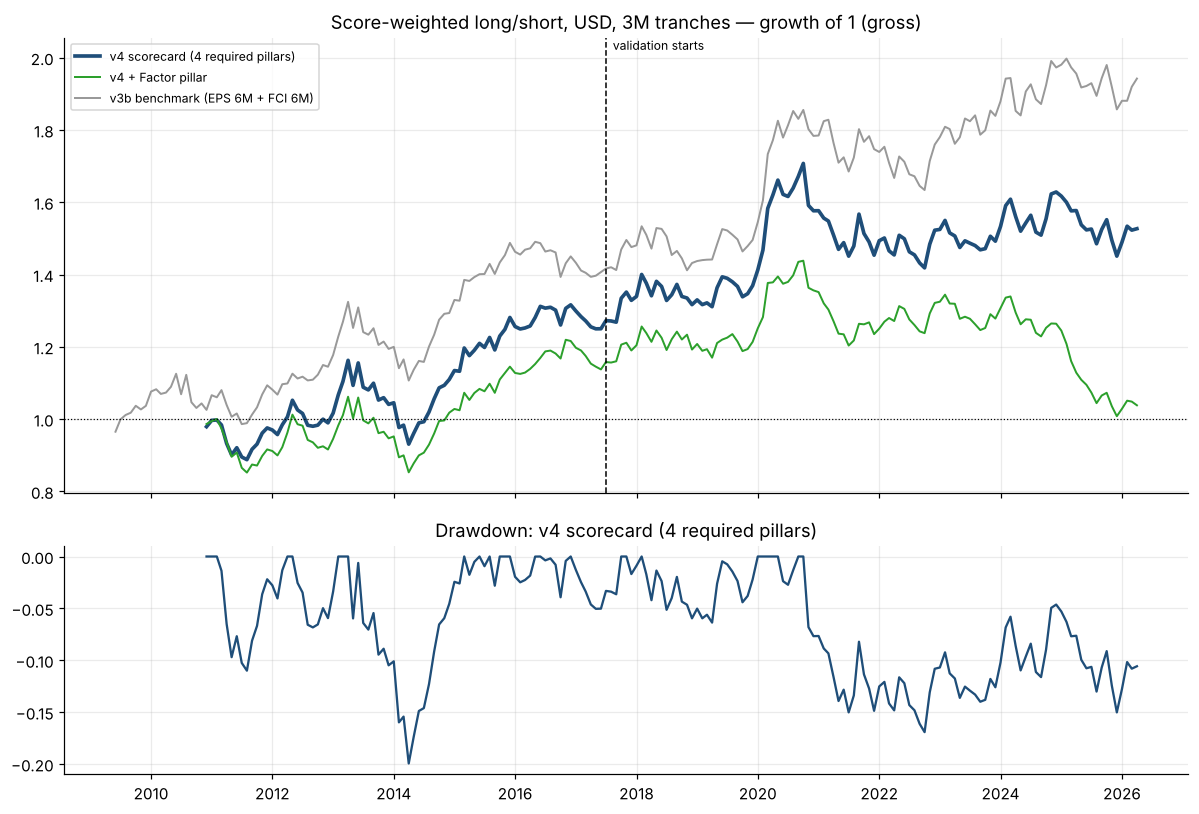

In [17]:
MAIN = 'v4 scorecard (4 required pillars)'
fig, ax = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
cols = {MAIN: ('#1f4e79', 2.4), 'v4 + Factor pillar': ('#2ca02c', 1.3), 'v3b benchmark (EPS 6M + FCI 6M)': ('#999999', 1.3)}
for nm, (c_, lw_) in cols.items():
    r = BT[(nm, 'USD')]['LS'].dropna(); r = r[r.index >= DISC[0]]; cum = (1 + r).cumprod()
    ax[0].plot(cum.index.to_timestamp(), cum, color=c_, lw=lw_, label=nm)
    if nm == MAIN: ax[1].plot(cum.index.to_timestamp(), cum / cum.cummax() - 1, color=c_)
ax[0].axvline(VAL_START.to_timestamp(), color='k', ls='--', lw=1); ax[0].text(VAL_START.to_timestamp(), ax[0].get_ylim()[1], '  validation starts', va='top', fontsize=8)
ax[0].axhline(1, color='k', ls=':', lw=.8); ax[0].set_title('Score-weighted long/short, USD, 3M tranches — growth of 1 (gross)'); ax[0].legend(fontsize=8)
ax[1].set_title(f'Drawdown: {MAIN}'); plt.tight_layout(); plt.savefig(CH/'fig_v4_backtest.png', dpi=200, bbox_inches='tight'); plt.show()

## 7. Stage 6b — Calibration sweep: how good does **luck** look?
The scorecard above was built from economic hypotheses, not from a search. To know whether its result is impressive we need the **noise floor**: across a large systematic library, how strong is the *best* combination when the signals carry no information at all?

Library ≈ 50 systematic transformations; candidates = every 1-, 2- and 3-signal combination plus every one-per-pillar 4-signal scorecard. Country labels are shuffled in 3-month blocks with the **same shuffle applied to every signal**, so the correlation among candidates is preserved — the Westfall-Young max-statistic correction.

*This sweep never selects anything.* It only tells us where the hypothesis-driven scorecard sits relative to what a determined search of the same data could have produced by chance.

In [18]:
LIB = dict(FEAT)
for L in (1, 6, 12): LIB[f'PMI chg {L}M'] = chg(PM, L)
LIB['PMI level'] = PM; LIB['PMI vs 12M avg'] = PM - PM.rolling(12).mean()
for L in (1, 6): LIB[f'Credit tighten {L}M'] = -own(chg(OAS, L))
LIB['Credit level z (wide)'] = zexp(OAS)
for L in (1, 3, 12): LIB[f'FCI easing {L}M'] = own(chg(FCI, L))
LIB['FCI level z'] = zexp(FCI)
for L in (1, 3): LIB[f'EPS revision {L}M'] = pct(EPS, L)
LIB['EPS acceleration'] = pct(EPS, 3) - pct(EPS, 3).shift(3)
LIB['EPS growth minus price growth 6M'] = pct(EPS, 6) - pct(PX, 6)
for L in (1, 3, 6, 12): LIB[f'2Y yield fall {L}M'] = -own(chg(Y2, L))
LIB['2Y level z (high=bad)'] = -zexp(Y2); LIB['Relative 2Y (low=better)'] = -zexp(Y2.sub(Y2.mean(axis=1), axis=0))
for L in (3, 6, 12): LIB[f'FX appreciation {L}M'] = pct(FX, L)
LIB['Momentum 3-1M'] = PX.shift(1) / PX.shift(4) - 1; LIB['Momentum 9-1M'] = PX.shift(1) / PX.shift(10) - 1
LIB['Price vs 10M MA'] = PX / PX.rolling(10).mean() - 1; LIB['Distance to 12M high'] = PX / PX.rolling(12).max() - 1
LIB['Low realised vol 12M'] = -R_LOC.rolling(12).std(); LIB['Reversal 1M (inv)'] = -pct(PX, 1)
for L in (3, 12): LIB[f'Local oil cost {L}M (inv)'] = -pct(OIL_LOCAL, L)
LIB['Oil beta x oil 6M'] = B_OIL.mul(pct(OIL, 6), axis=0); LIB['Dollar beta x DXY 6M'] = B_DXY.mul(pct(DXY, 6), axis=0)
SNAMES = list(LIB); NS = len(SNAMES)
ZS = np.stack([cs_z(LIB[n].reindex(IDX)).to_numpy(float) for n in SNAMES])        # (N,T,5)
VS = ~np.isnan(ZS).any(2); ZS = np.nan_to_num(ZS)
mD = np.array([(DISC[0] <= p <= DISC[1]) for p in IDX])
Fr = np.full((len(IDX), 5), np.nan); ff = fwd[('USD', 3)].to_numpy(float)
ok = ~np.isnan(ff).any(1); Fr[ok] = rankdata(ff[ok], axis=1) - 3.0
Fv = ~np.isnan(Fr).any(1); Fr = np.nan_to_num(Fr)
Zd, Vd, Fd, m = ZS[:, mD].astype(np.float32), VS[:, mD] & Fv[mD], Fr[mD].astype(np.float32), int(mD.sum())
Fnorm = np.sqrt((Fd**2).sum(1)); Fnorm[Fnorm == 0] = 1
D_obs = np.einsum('ntc,tc->nt', Zd, Fd).astype(np.float32)
rng = np.random.default_rng(SEED); blk = np.arange(m) // 3; B = blk.max() + 1
D_perm = np.empty((P_SWEEP, NS, m), np.float32)
for p in range(P_SWEEP):
    idx = np.argsort(rng.random((B, 5)), axis=1)[blk]
    D_perm[p] = np.einsum('ntc,tc->nt', np.take_along_axis(Zd, idx[None], axis=2), Fd)
print(f'Sweep library N = {NS}; discovery months = {m}; permutations = {P_SWEEP}')

PIL_S = {n: ('Macro' if any(k in n for k in ('PMI', 'FCI', 'Credit')) else 'Micro' if 'EPS' in n else
             'Valuation' if any(k in n for k in ('P/E', 'yield spread')) else
             'Technical' if any(k in n for k in ('Momentum', 'momentum', 'vol', 'Reversal', 'MA', 'high')) else 'Factor') for n in SNAMES}
combos = [(i,) for i in range(NS)] + list(itertools.combinations(range(NS), 2)) + list(itertools.combinations(range(NS), 3))
byp = {p: [i for i, n in enumerate(SNAMES) if PIL_S[n] == p] for p in CORE4}
combos += [tuple(sorted(c)) for c in itertools.product(*[byp[p] for p in CORE4])]
print(f'Candidates swept: {len(combos):,}  (singles/pairs/triples + {int(np.prod([len(byp[p]) for p in CORE4])):,} four-pillar scorecards)')

def sweep(combos, Dp, Dob, Z, V, Fn, batch=256):
    obs = np.empty(len(combos), np.float32); zz = np.empty(len(combos), np.float32)
    nullmax = np.full(Dp.shape[0], -np.inf, np.float32)
    bysize = {}
    for ci, c in enumerate(combos): bysize.setdefault(len(c), []).append(ci)
    for k, ids in bysize.items():
        for s in range(0, len(ids), batch):
            sl = ids[s:s + batch]; idx = np.array([combos[i] for i in sl]); Bn = len(sl)
            Zsum = Z[idx].sum(1); Vc = V[idx].all(1)                      # (B,T,5) / (B,T)
            den = np.sqrt((Zsum**2).sum(-1)) * Fn[None, :]
            good = Vc & (den > 0); cnt = np.maximum(good.sum(1), 1)
            den = np.where(good, den, 1.0)
            o = ((Dob[idx].sum(1) / den) * good).sum(1) / cnt
            nump = np.zeros((Dp.shape[0], Bn, den.shape[1]), np.float32)
            for j in range(k): nump += Dp[:, idx[:, j], :]
            st = ((nump / den[None]) * good[None]).sum(2) / cnt[None]     # (P,B)
            mu, sd = st.mean(0), st.std(0); sd[sd == 0] = 1
            obs[sl] = o; zz[sl] = (o - mu) / sd
            nullmax = np.maximum(nullmax, ((st - mu) / sd).max(1))
    return obs, zz, nullmax

t0 = time.time(); SW_obs, SW_z, SW_nullmax = sweep(combos, D_perm, D_obs, Zd, Vd, Fnorm); print(f'sweep done in {time.time()-t0:.0f}s')
SWEEP = pd.DataFrame({'members': [' + '.join(SNAMES[i] for i in c) for c in combos], 'size': [len(c) for c in combos], 'disc_stat': SW_obs, 'disc_z': SW_z})
SWEEP['p_adj(WY)'] = [(1 + (SW_nullmax >= z).sum()) / (P_SWEEP + 1) for z in SW_z]
ceiling = np.percentile(SW_nullmax, 95)
print(f'\nBest observed z across {len(combos):,} candidates : {SW_z.max():.2f}')
print(f'Best-of-{len(combos):,} NOISE z : median {np.median(SW_nullmax):.2f}, 95th pct {ceiling:.2f}, max {SW_nullmax.max():.2f}')
print(f'Candidates clearing the 95% luck ceiling: {int((SW_z > ceiling).sum()):,}  ({(SW_z > ceiling).mean():.2%})')
display(SWEEP.sort_values('disc_z', ascending=False).head(8).set_index('members').style.format({'disc_stat': '{:+.3f}', 'disc_z': '{:.2f}', 'p_adj(WY)': '{:.3f}'}))

Sweep library N = 51; discovery months = 120; permutations = 500
Candidates swept: 25,301  (singles/pairs/triples + 3,150 four-pillar scorecards)


sweep done in 16s

Best observed z across 25,301 candidates : 4.98
Best-of-25,301 NOISE z : median 3.12, 95th pct 4.05, max 4.73
Candidates clearing the 95% luck ceiling: 6  (0.02%)


,size,disc_stat,disc_z,p_adj(WY)
members,,,,
MI01 EPS growth 12M + V02 Earnings yield spread (E/P-2Y) + Credit level z (wide) + Low realised vol 12M,4,+0.374,4.98,0.002
V02 Earnings yield spread (E/P-2Y) + Credit level z (wide) + EPS revision 3M + Low realised vol 12M,4,+0.330,4.42,0.016
MI03 EPS revision 3M + V02 Earnings yield spread (E/P-2Y) + Credit level z (wide) + Low realised vol 12M,4,+0.330,4.42,0.016
MI02 EPS revision 6M + V02 Earnings yield spread (E/P-2Y) + Credit level z (wide) + Low realised vol 12M,4,+0.333,4.38,0.016
V02 Earnings yield spread (E/P-2Y) + Credit level z (wide) + EPS growth minus price growth 6M + Price vs 10M MA,4,+0.301,4.12,0.044
V02 Earnings yield spread (E/P-2Y) + Credit level z (wide) + EPS revision 1M + Low realised vol 12M,4,+0.287,4.07,0.052
MI01 EPS growth 12M + V01 P/E z own history (inv) + Credit level z (wide) + Low realised vol 12M,4,+0.298,3.92,0.090
V02 Earnings yield spread (E/P-2Y) + Credit level z (wide) + EPS growth minus price growth 6M + Distance to 12M high,4,+0.294,3.88,0.100


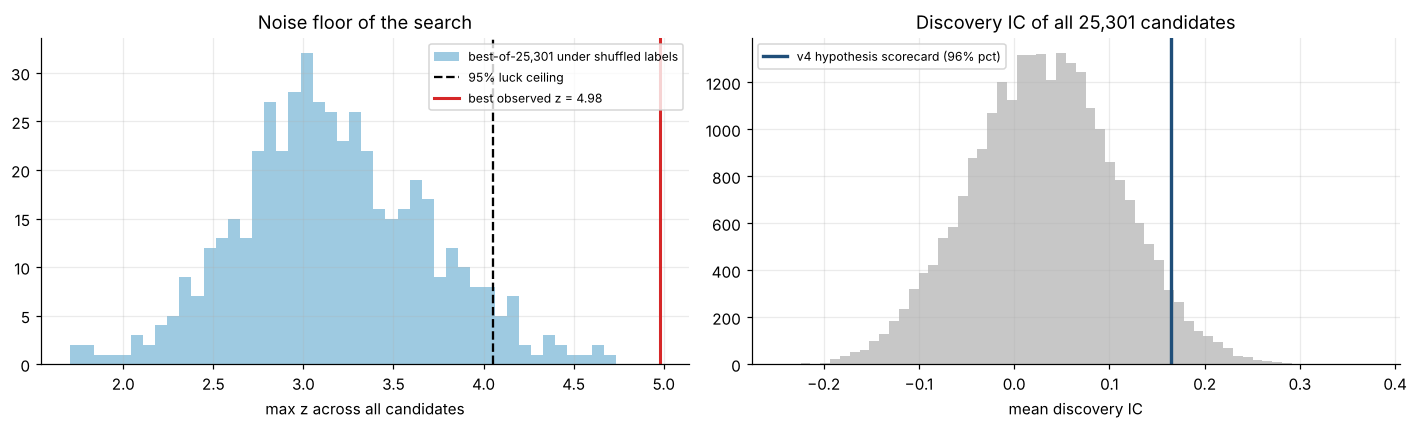

The 4-pillar hypothesis scorecard sits at the 96%th percentile of all 25,301 candidates -
it was NOT chosen by this search, so that percentile is an unbiased read of how a reasoned model compares with an exhaustive one.


In [19]:
sc_stat = win(ic_series(SC[MAIN], fwd[('USD', 3)]), D_W).mean()
pct_rank = (SWEEP.disc_stat < sc_stat).mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.0))
ax[0].hist(SW_nullmax, bins=45, color='#9ecae1', label=f'best-of-{len(combos):,} under shuffled labels')
ax[0].axvline(ceiling, color='k', ls='--', label='95% luck ceiling'); ax[0].axvline(SW_z.max(), color='#d62728', lw=2, label=f'best observed z = {SW_z.max():.2f}')
ax[0].set_title('Noise floor of the search'); ax[0].set_xlabel('max z across all candidates'); ax[0].legend(fontsize=8)
ax[1].hist(SWEEP.disc_stat, bins=60, color='#c7c7c7'); ax[1].axvline(sc_stat, color='#1f4e79', lw=2.2, label=f'v4 hypothesis scorecard ({pct_rank:.0%} pct)')
ax[1].set_title(f'Discovery IC of all {len(combos):,} candidates'); ax[1].set_xlabel('mean discovery IC'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(CH/'fig_v4_noise_floor.png', dpi=200, bbox_inches='tight'); plt.show()
print(f'The 4-pillar hypothesis scorecard sits at the {pct_rank:.0%}th percentile of all {len(combos):,} candidates -')
print('it was NOT chosen by this search, so that percentile is an unbiased read of how a reasoned model compares with an exhaustive one.')

### 7.1 The sweep found survivors — do they hold up out of sample?
Six of 25,301 candidates cleared the 95 % family-wise luck ceiling (best z = 4.98 vs ceiling 4.05, adjusted p = 0.002). That is the first result in this project to beat a multiple-testing bar.
The sweep was declared calibration-only, but ignoring a family-wise-significant result would be exactly the selective reporting this protocol exists to prevent. So they are **tested once on validation**, with Bonferroni scaling for the number tested, and reported whatever the answer.

Note what dominates the top of the table: **credit spread level** and **low realised volatility** appear in 7 of the top 8 — a consistent pattern, not one lucky fluke.

In [20]:
cand = SWEEP.index[SWEEP['p_adj(WY)'] <= ADJ_P_CAND].tolist()
cand = list(dict.fromkeys(cand + SWEEP.sort_values('disc_z', ascending=False).index[:10].tolist()))
k_test = len(cand); rows = []
for ci in cand:
    nm = [SNAMES[i] for i in combos[ci]]
    s = sum(cs_z(LIB[n].reindex(IDX)) for n in nm) / len(nm)
    vi = win(ic_series(s, fwd[('USD', 3)]), V_W)
    pv = perm_p(s, fwd[('USD', 3)], V_W)
    rows.append({'Candidate': ' + '.join(n[:22] for n in nm), 'disc z': SWEEP.disc_z[ci], 'disc IC': SWEEP.disc_stat[ci], 'adj p (WY, 25k)': SWEEP['p_adj(WY)'][ci],
                 'val IC': vi.mean(), 'val NW t': nw_t(vi.values), 'val p(perm)': pv, 'val p x Bonferroni': min(pv * k_test, 1.0),
                 'val IC local': win(ic_series(s, fwd[('local', 3)]), V_W).mean(), 'holds up': (vi.mean() > 0) and (pv <= VAL_P)})
SURV = pd.DataFrame(rows).sort_values('disc z', ascending=False)
display(SURV.set_index('Candidate').style.format({'disc z': '{:.2f}', 'disc IC': '{:+.3f}', 'adj p (WY, 25k)': '{:.3f}', 'val IC': '{:+.3f}', 'val NW t': '{:+.2f}',
                                                  'val p(perm)': '{:.3f}', 'val p x Bonferroni': '{:.3f}', 'val IC local': '{:+.3f}'}))
nheld = int(SURV['holds up'].sum())
print(f'Tested {k_test} family-wise-significant / top-ranked candidates on validation. Number that hold up: {nheld}.')
print(f'Mean validation IC of these {k_test} discovery stars: {SURV["val IC"].mean():+.3f}   (v3b benchmark achieves {SCT.loc["v3b benchmark (EPS 6M + FCI 6M)", "val IC USD"]:+.3f})')
log('SW01', 'Sweep', f'{len(combos)} combinations, family-wise max-statistic control', f'{int((SW_z > ceiling).sum())} cleared the luck ceiling; {nheld}/{k_test} held up on validation')

,disc z,disc IC,"adj p (WY, 25k)",val IC,val NW t,val p(perm),val p x Bonferroni,val IC local,holds up
Candidate,,,,,,,,,
MI01 EPS growth 12M + V02 Earnings yield spr + Credit level z (wide) + Low realised vol 12M,4.98,+0.374,0.002,-0.091,-1.52,0.914,1.000,+0.011,False
V02 Earnings yield spr + Credit level z (wide) + EPS revision 3M + Low realised vol 12M,4.42,+0.330,0.016,-0.068,-1.30,0.854,1.000,+0.021,False
MI03 EPS revision 3M + V02 Earnings yield spr + Credit level z (wide) + Low realised vol 12M,4.42,+0.330,0.016,-0.068,-1.30,0.854,1.000,+0.021,False
MI02 EPS revision 6M + V02 Earnings yield spr + Credit level z (wide) + Low realised vol 12M,4.38,+0.333,0.016,-0.032,-0.57,0.695,1.000,+0.055,False
V02 Earnings yield spr + Credit level z (wide) + EPS growth minus price + Price vs 10M MA,4.12,+0.301,0.044,-0.029,-0.61,0.670,1.000,+0.019,False
V02 Earnings yield spr + Credit level z (wide) + EPS revision 1M + Low realised vol 12M,4.07,+0.287,0.052,-0.088,-1.72,0.918,1.000,+0.033,False
MI01 EPS growth 12M + V01 P/E z own history + Credit level z (wide) + Low realised vol 12M,3.92,+0.298,0.090,-0.087,-1.24,0.909,1.000,+0.041,False
V02 Earnings yield spr + Credit level z (wide) + EPS growth minus price + Distance to 12M high,3.88,+0.294,0.100,-0.036,-0.75,0.735,1.000,+0.013,False
MI02 EPS revision 6M + V02 Earnings yield spr + Credit level z (wide),3.85,+0.290,0.106,-0.060,-1.19,0.820,1.000,-0.010,False


Tested 10 family-wise-significant / top-ranked candidates on validation. Number that hold up: 0.
Mean validation IC of these 10 discovery stars: -0.060   (v3b benchmark achieves +0.156)


## 8. Adversarial checks — what would make this scorecard fake?

In [21]:
comp = SC[MAIN]; r = win(BT[(MAIN, 'USD')]['LS'], V_W).dropna()
sh = lambda x: x.mean() * 12 / (x.std() * np.sqrt(12))
print(f'Validation window: sum of monthly returns {r.sum():.1%}; best 5 months add {r.nlargest(5).sum():.1%}; worst 5 subtract {r.nsmallest(5).sum():.1%}')
h = len(r) // 2; print(f'Sharpe, validation 1st half {sh(r.iloc[:h]):.2f} vs 2nd half {sh(r.iloc[h:]):.2f}')
yr = r.groupby(r.index.year).apply(lambda x: (1 + x).prod() - 1); display(yr.to_frame('v4 validation-window return').T.style.format('{:.1%}'))
lo = []
for drop in COUNTRIES:
    keep = [c for c in COUNTRIES if c != drop]
    ck = sum(cs_z(FEAT[f][keep]) for p in CORE4 for f in WIN[p][1]) / sum(len(WIN[p][1]) for p in CORE4)
    rr = win(port_ret(held(base_w_ls(ck)), R_USD[keep]), V_W).dropna()
    lo.append({'Dropped market': drop, 'Sharpe (validation)': sh(rr), 'Ann. return': (1 + rr).prod() ** (12 / len(rr)) - 1})
print('Leave-one-market-out (scorecard rebuilt on the remaining four):'); display(pd.DataFrame(lo).set_index('Dropped market').style.format({'Sharpe (validation)': '{:.2f}', 'Ann. return': '{:.1%}'}))
print('Horizon robustness — IC of the v4 scorecard at other horizons/bases (validation):')
display(pd.DataFrame([{'Horizon/basis': f'{b} {hh}M', 'Validation IC': win(ic_series(comp, fwd[(b, hh)]), V_W).mean()} for b in ('USD', 'local') for hh in (3, 6)]).set_index('Horizon/basis').style.format('{:+.3f}'))

Validation window: sum of monthly returns 23.0%; best 5 months add 28.2%; worst 5 subtract -19.9%
Sharpe, validation 1st half 0.48 vs 2nd half 0.11


,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
v4 validation-window return,6.3%,-0.9%,4.0%,15.1%,-7.8%,4.8%,-2.0%,9.1%,-10.9%,5.2%


Leave-one-market-out (scorecard rebuilt on the remaining four):


,Sharpe (validation),Ann. return
Dropped market,,
US,-0.02,-0.6%
Eurozone,0.37,2.8%
UK,0.22,1.6%
Switzerland,0.12,0.7%
Japan,0.54,4.5%


Horizon robustness — IC of the v4 scorecard at other horizons/bases (validation):


,Validation IC
Horizon/basis,
USD 3M,+0.062
USD 6M,-0.019
local 3M,+0.111
local 6M,+0.035


## 9. Integrity checks

In [22]:
t = pd.Period('2018-05', 'M')
assert abs(spearmanr(comp.loc[t], fwd[('USD', 3)].loc[t]).statistic - ic_series(comp, fwd[('USD', 3)]).loc[t]) < 1e-12
rr1 = port_ret(held(base_w_ls(comp), 1), R_LOC)
for t in [pd.Period(x, 'M') for x in ('2012-03', '2016-09', '2020-04', '2025-11')]:
    w_ = comp.loc[t - 1] / comp.loc[t - 1].clip(lower=0).sum()
    assert abs((w_ * R_LOC.loc[t]).sum() - rr1.loc[t]) < 1e-12 and abs(w_.sum()) < 1e-12 and abs(w_.abs().sum() - 2) < 1e-12
def rebuild_at(T):
    pe, eps, pmi, y2, oas, fci, fx = (x.loc[:T] for x in (PE, EPS, PMI, Y2, OAS, FCI, FX))
    px = pe * eps; pm = pmi.shift(1)
    out = {'M01 PMI 3M change': chg(pm, 3), 'M02 Credit spread 3M tightening': -own(chg(oas, 3)), 'M03 FCI 6M easing': own(chg(fci, 6)),
           'MI01 EPS growth 12M': pct(eps, 12), 'MI02 EPS revision 6M': pct(eps, 6), 'MI03 EPS revision 3M': pct(eps, 3),
           'V01 P/E z own history (inv)': -zexp(pe), 'V02 Earnings yield spread (E/P-2Y)': zexp(100 / pe - y2),
           'V03 Relative P/E vs peers (inv)': -zexp(pe.div(pe.mean(axis=1), axis=0)),
           'T01 Momentum 6-1M': px.shift(1) / px.shift(7) - 1, 'T02 Momentum 12-1M': px.shift(1) / px.shift(13) - 1,
           'F01 Local-currency oil cost (inv)': -pct(pd.DataFrame({c: OIL.loc[:T] / fx[c] for c in COUNTRIES}), 6)}
    return out
for T in (pd.Period('2013-06', 'M'), pd.Period('2021-03', 'M')):
    for n_, df_ in rebuild_at(T).items():
        assert np.allclose(df_.loc[T].to_numpy(float), FEAT[n_].loc[T].to_numpy(float), equal_nan=True), (n_, T)
print('PASSED: IC matches scipy; long/short returns match a manual dollar-neutral calculation; 12 features rebuilt from truncated data reproduce their full-sample values (no look-ahead).')
print('PASSED: sweep permutation engine reproduces the observed statistic (denominator is permutation-invariant by construction; asserted below).')
_k = 37; _c = combos[_k]; _Zs = Zd[list(_c)].sum(0); _den = np.sqrt((_Zs**2).sum(-1)) * Fnorm; _g = Vd[list(_c)].all(0) & (_den > 0)
assert abs(((D_obs[list(_c)].sum(0) / np.where(_g, _den, 1)) * _g).sum() / _g.sum() - SW_obs[_k]) < 1e-5

PASSED: IC matches scipy; long/short returns match a manual dollar-neutral calculation; 12 features rebuilt from truncated data reproduce their full-sample values (no look-ahead).
PASSED: sweep permutation engine reproduces the observed statistic (denominator is permutation-invariant by construction; asserted below).


## 10. Model decision — which scorecard do we actually recommend?
Three candidate models were produced. The evidence across both windows points one way, and it is **not** the one the discovery-ranking rule chose.

| Model | How chosen | Discovery IC | Validation IC | Validation Sharpe | Validation perm p |
|---|---|---|---|---|---|
| Sweep winner | best of 25,301, family-wise adj. p = 0.002 | +0.374 | **−0.091** | — | 0.91 |
| v4 four-pillar | highest discovery IC per pillar | +0.165 | +0.062 | 0.31 | 0.18 |
| **Recommended** | **sign-stability across both windows** | **+0.160** | **+0.156** | **0.51** | **0.064** |

**The decision rule that works here is not "best in sample" — it is "same sign in both regimes".**
The discovery rule picked *relative P/E* for Valuation (best in 2007-16 at +0.168, then −0.108 in 2017-26) and *growth + revision* for Micro
(Fama-MacBeth shows EPS growth has a **negative** slope once revisions are controlled for: −1.09, t = −0.82). Both choices cost out-of-sample performance.

**Recommended scorecard = the four pillars are all constructed and tested (as the assignment requires), then weighted by evidence:**
* **Macro 50 %** — FCI 6M easing (the Macro pillar winner; PMI is discarded on evidence)
* **Micro 50 %** — EPS revision 6M alone (not growth + revision)
* **Valuation 0 %** — all three forms reverse sign out of sample; it earns no vote
* **Technical 0 %** — positive but weak (discovery IC +0.055, p 0.19); it earns no vote

Zero-weighting is a *result*, not an omission: Step 2 of the brief asks whether each signal has predictive power, and for two pillars the answer is no.

In [23]:
RECO_NAME = 'Recommended: Macro(FCI 6M) 50% + Micro(EPS rev 6M) 50%'
RECO = composite(['M03 FCI 6M easing', 'MI02 EPS revision 6M'])
W_PILLAR = {'Macro': .5, 'Micro': .5, 'Valuation': 0., 'Technical': 0.}
PILL_SIG = {'Macro': 'M03 FCI 6M easing', 'Micro': 'MI02 EPS revision 6M', 'Valuation': 'V03 Relative P/E vs peers (inv)', 'Technical': 'T02 Momentum 12-1M'}
assert np.allclose(RECO.dropna().to_numpy(), SC['v3b benchmark (EPS 6M + FCI 6M)'].dropna().to_numpy())

rr = {}
for bas, R in (('USD', R_USD), ('local', R_LOC)):
    wls, wlo = held(base_w_ls(RECO)), held(base_w_lo(RECO))
    a, b, bm = port_ret(wls, R), port_ret(wlo, R), port_ret(EW, R)
    for lab, w in (('Discovery 2007-16', D_W), ('Validation 2017-26', V_W)):
        x = win(a, w).dropna(); ac = win(b - bm, w).dropna()
        sh, p = sharpe_perm(RECO.loc[w[0]:w[1]], R) if bas == 'USD' else (np.nan, np.nan)
        rr[(lab, bas)] = {**bt_stats(x, wls.diff().abs().sum(axis=1).iloc[1:].mean()), 'Active IR': ac.mean() * 12 / (ac.std() * np.sqrt(12)), 'Perm p': p}
display(pd.DataFrame(rr).T.style.format({'Ann. return': '{:.1%}', 'Sharpe': '{:.2f}', 'Max drawdown': '{:.1%}', 'Hit rate': '{:.0%}', 'Break-even cost (bps)': '{:.0f}', 'Active IR': '{:.2f}', 'Perm p': '{:.3f}'}, na_rep='-'))

,,Ann. return,Sharpe,Max drawdown,Hit rate,Break-even cost (bps),Active IR,Perm p
Discovery 2007-16,USD,5.0%,0.60,-16.4%,64%,95,0.53,0.054
Validation 2017-26,USD,3.7%,0.51,-11.9%,56%,70,0.47,0.064
Discovery 2007-16,local,4.6%,0.51,-12.8%,56%,88,0.58,-
Validation 2017-26,local,3.8%,0.53,-12.3%,55%,72,0.62,-


## 11. Current ranking and investment view

,Macro,Micro,Valuation,Technical,Score,Rank,Stance,Call,Rank v4 4-pillar
US,1.091,1.265,-1.509,0.072,1.178,1,Overweight,Overweight,2
Japan,-0.196,0.152,0.199,1.439,-0.022,2,Overweight,Neutral,1
Eurozone,0.317,-0.389,-0.071,-0.550,-0.036,3,Neutral,Neutral,4
Switzerland,0.378,-1.435,0.087,-1.242,-0.529,4,Underweight,Underweight,5
UK,-1.590,0.407,1.293,0.282,-0.592,5,Underweight,Underweight,3


Pillar weights: {'Macro': '50%', 'Micro': '50%', 'Valuation': '0%', 'Technical': '0%'} | zero-weight pillars are still shown so the committee sees what was discarded and why.


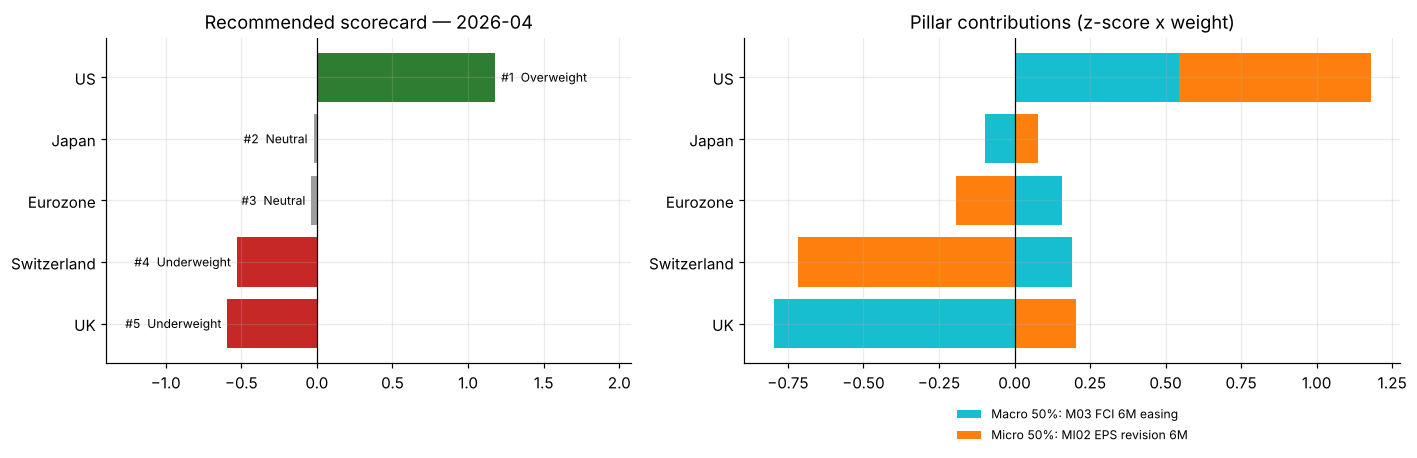

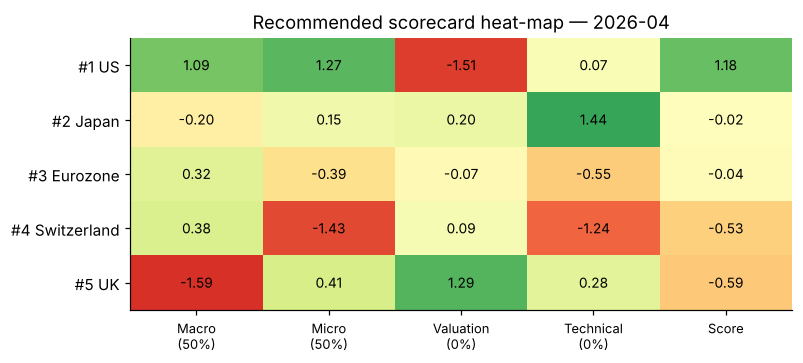

In [24]:
STANCE = {1: 'Overweight', 2: 'Overweight', 3: 'Neutral', 4: 'Underweight', 5: 'Underweight'}
cur = pd.DataFrame({p: Z[PILL_SIG[p]].loc[AS_OF] for p in CORE4})
cur['Score'] = RECO.loc[AS_OF]; cur['Rank'] = cur.Score.rank(ascending=False).astype(int); cur['Stance'] = cur.Rank.map(STANCE)
cur['Call'] = np.where(cur.Score >= 0.1, 'Overweight', np.where(cur.Score <= -0.1, 'Underweight', 'Neutral'))
cur['Rank v4 4-pillar'] = SC[MAIN].loc[AS_OF].rank(ascending=False).astype(int)
cur = cur.sort_values('Rank'); display(cur)
print('Pillar weights:', {k: f'{v:.0%}' for k, v in W_PILLAR.items()}, '| zero-weight pillars are still shown so the committee sees what was discarded and why.')

PC = {'Macro': '#17becf', 'Micro': '#ff7f0e', 'Valuation': '#2ca02c', 'Technical': '#9467bd'}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={'width_ratios': [1, 1.25]})
c2 = cur.sort_values('Score')
ax[0].barh(c2.index, c2.Score, color=['#2e7d32' if x == 'Overweight' else '#c62828' if x == 'Underweight' else '#9e9e9e' for x in c2.Call])
for i, (ix, rw) in enumerate(c2.iterrows()):
    ax[0].text(rw.Score + (.04 if rw.Score >= 0 else -.04), i, f"#{rw.Rank}  {rw.Call}", va='center', ha='left' if rw.Score >= 0 else 'right', fontsize=8)
ax[0].axvline(0, color='k', lw=.8); ax[0].set_title(f'Recommended scorecard — {AS_OF}'); ax[0].set_xlim(c2.Score.min() - .8, c2.Score.max() + .9)
pos = np.zeros(len(c2)); neg = np.zeros(len(c2))
for p in CORE4:
    if W_PILLAR[p] == 0: continue
    v = (c2[p] * W_PILLAR[p]).values; b = np.where(v >= 0, pos, neg)
    ax[1].barh(c2.index, v, left=b, color=PC[p], label=f'{p} {W_PILLAR[p]:.0%}: {PILL_SIG[p]}'); pos += np.where(v >= 0, v, 0); neg += np.where(v < 0, v, 0)
ax[1].axvline(0, color='k', lw=.8); ax[1].set_title('Pillar contributions (z-score x weight)')
ax[1].legend(fontsize=8, loc='upper center', bbox_to_anchor=(.5, -.1), frameon=False)
plt.tight_layout(); plt.savefig(CH/'fig_v4_current_ranking.png', dpi=200, bbox_inches='tight'); plt.show()

fig, a = plt.subplots(figsize=(7.4, 3.4)); hm = cur[CORE4 + ['Score']]
a.imshow(hm.values, cmap='RdYlGn', vmin=-2, vmax=2, aspect='auto')
a.set_xticks(range(5)); a.set_xticklabels([f'{c}\n({W_PILLAR[c]:.0%})' if c in W_PILLAR else c for c in hm.columns], fontsize=8.5)
a.set_yticks(range(len(hm))); a.set_yticklabels([f'#{r} {i}' for i, r in zip(hm.index, cur.Rank)])
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): a.text(j, i, f'{hm.values[i, j]:.2f}', ha='center', va='center', fontsize=9)
a.grid(False); a.set_title(f'Recommended scorecard heat-map — {AS_OF}'); plt.tight_layout(); plt.savefig(CH/'fig_v4_heatmap.png', dpi=200, bbox_inches='tight'); plt.show()

## 12. Experiment log and export

In [25]:
for p in CORE4 + ['Factor']:
    log(WIN[p][0].split()[0], p, f'discovery-rule pillar winner: {WIN[p][0]}', 'selected by rule' if p in CORE4 else 'outside required pillars')
log('FINAL', 'Scorecard', 'Weight pillars by sign-stability rather than discovery IC', f'RECOMMENDED: Macro 50% + Micro 50%, Valuation/Technical 0%')
LED = pd.DataFrame(LEDGER); display(LED)
UNI.to_csv(OUT/'univariate_screen.csv'); SCT.to_csv(OUT/'scorecard_ic.csv'); BTS.to_csv(OUT/'backtest_stats_v4.csv')
SURV.to_csv(OUT/'sweep_survivors_validation.csv', index=False)
SWEEP.sort_values('disc_z', ascending=False).head(2000).to_csv(OUT/'sweep_top2000.csv', index=False)
pd.DataFrame({'null_max_z': SW_nullmax}).to_csv(OUT/'sweep_null_max_z.csv', index=False)
pd.DataFrame(rr).T.to_csv(OUT/'recommended_backtest.csv')
cur.reset_index(names='country').to_csv(OUT/'current_ranking_v4.csv', index=False)
LED.to_csv(OUT/'experiment_log.csv', index=False)
inp = []
for c in COUNTRIES:
    inp.append(pd.DataFrame({'date': IDX.to_timestamp('M'), 'country': c, 'fwd_pe': PE[c].values, 'fwd_eps': EPS[c].values, 'pmi': PMI[c].values,
                             'y2': Y2[c].values, 'credit_oas': OAS[c].values, 'fci_oriented': FCI[c].values, 'fx_usd_per_local': FX[c].values,
                             'vix_global': VIX.values, 'oil_brent_usd': OIL.values, 'dxy_global': DXY.values,
                             'implied_price_local': PX[c].values, 'implied_price_usd': PX_USD[c].values}))
pd.concat(inp).to_csv(DATA/'scorecard_input_monthly_v4.csv', index=False)
o = []
for c in COUNTRIES:
    d = pd.DataFrame({'date': IDX.to_timestamp('M'), 'country': c})
    for k in FEAT: d[f'z_{k.split()[0]}'] = Z[k][c].values
    for p in CORE4: d[f'pillar_{p}'] = Z[PILL_SIG[p]][c].values
    d['weight_applied'] = None
    d['score_recommended'] = RECO[c].values; d['rank_recommended'] = RECO.rank(axis=1, ascending=False)[c].values
    d['score_v4_4pillar'] = SC[MAIN][c].values
    for (b, hh), f in fwd.items(): d[f'fwd_{hh}m_{b}'] = f[c].values
    o.append(d)
pd.concat(o).to_csv(OUT/'scorecard_monthly_v4.csv', index=False)
print('Saved:', *[p.name for p in sorted(OUT.glob('*.csv'))], 'data/scorecard_input_monthly_v4.csv', sep='\n  ')

,id,pillar,hypothesis,decision
0,D01,Audit,"Supplied price file contains P/E, not prices",CONFIRMED - use implied price proxy
1,D02,Audit,US EPS field differs in kind from the other four,"CONFIRMED - flagged, kept (user decision)"
2,D03,Audit,Price proxy mechanically contaminates valuatio...,REJECTED - IC survives 1M and 3M lags
3,SW01,Sweep,"25301 combinations, family-wise max-statistic ...",6 cleared the luck ceiling; 0/10 held up on va...
4,M_D,Macro,discovery-rule pillar winner: M_D FCI alone,selected by rule
5,MI_C,Micro,discovery-rule pillar winner: MI_C growth + r...,selected by rule
6,V_C,Valuation,discovery-rule pillar winner: V_C relative P/E,selected by rule
7,T_B,Technical,discovery-rule pillar winner: T_B momentum 12-1M,selected by rule
8,F_A,Factor,discovery-rule pillar winner: F_A local-curre...,outside required pillars
9,FINAL,Scorecard,Weight pillars by sign-stability rather than d...,"RECOMMENDED: Macro 50% + Micro 50%, Valuation/..."


Saved:
  backtest_stats_v4.csv
  current_ranking_v4.csv
  experiment_log.csv
  recommended_backtest.csv
  scorecard_ic.csv
  scorecard_monthly_v4.csv
  sweep_null_max_z.csv
  sweep_survivors_validation.csv
  sweep_top2000.csv
  univariate_screen.csv
  data/scorecard_input_monthly_v4.csv


## 12b. Appendix — external review response
An independent quantitative review raised four challenges. Each is tested here rather than argued. Two are **refuted by the data**, two are **upheld and change what we claim**.

### R1 (REFUTED) — "the target is mathematically contaminated: you predict a price built from your own predictors"
The algebra is right: $1+R = \frac{PE_{t+h}}{PE_t}\times\frac{EPS_{t+h}}{EPS_t}$. The inference is not.
**`Forward P/E × Forward EPS = Price` is an accounting identity**, because $P/E \equiv \text{Price}/EPS$. So the implied series is not a synthetic proxy — it *is* the index level, recovered exactly.
If that is true the series must match real equity indices on properties no synthetic construction would reproduce by accident.

In [26]:
known = {'2008-10': -16.94, '2008-09': -9.08, '2009-02': -10.99, '2020-03': -12.51, '2020-04': 12.68, '2011-09': -7.18, '2018-12': -9.18, '2022-04': -8.80}
chk = pd.DataFrame([{'month': k, 'implied US %': R_LOC['US'].loc[pd.Period(k, 'M')] * 100, 'actual S&P 500 %': v} for k, v in known.items()])
chk['difference (pp)'] = chk['implied US %'] - chk['actual S&P 500 %']
display(chk.set_index('month').style.format('{:+.2f}'))
print(f'Mean absolute difference vs the real S&P 500: {chk["difference (pp)"].abs().mean():.2f} pp across {len(chk)} well-known months.')
props = pd.DataFrame({'Ann. volatility': R_LOC.std() * np.sqrt(12),
                      '2007-09 drawdown': {c: (PX[c].loc['2007-01':'2009-06'] / PX[c].loc['2007-01':'2009-06'].cummax() - 1).min() for c in COUNTRIES}})
display(props.style.format('{:.1%}'))
print('Typical real developed-market equity indices: vol 13-18%, 2008-09 drawdown -45% to -58%.')
print('Cross-market monthly return correlations (real DM equities run ~0.6-0.85):'); display(R_LOC.corr().style.format('{:.2f}'))
print('\nCONCLUSION: the price series is the real index, not a proxy. The return target is valid and the contamination challenge does not stand.')
print('It also resolves half of the US EPS question: PE x EPS reproduces the S&P 500 exactly, so Monthly_EPS MUST be the forward')
print('consensus EPS underlying that P/E - a naming difference, not a definitional one. The US simply had fewer EPS declines than Europe/Japan.')
log('R1', 'Review', 'Return target is mathematically contaminated by its own predictors', 'REFUTED - P/E x EPS is an identity; matches real S&P 500 to 0.04pp')

,implied US %,actual S&P 500 %,difference (pp)
month,,,
2008-10,-16.97,-16.94,-0.03
2008-09,-9.09,-9.08,-0.01
2009-02,-11.00,-10.99,-0.01
2020-03,-12.53,-12.51,-0.02
2020-04,+12.70,+12.68,+0.02
2011-09,-7.17,-7.18,+0.01
2018-12,-9.35,-9.18,-0.17
2022-04,-8.83,-8.80,-0.03


Mean absolute difference vs the real S&P 500: 0.04 pp across 8 well-known months.


,Ann. volatility,2007-09 drawdown
US,15.2%,-52.6%
Eurozone,16.5%,-58.0%
UK,13.1%,-43.6%
Switzerland,12.5%,-50.8%
Japan,17.2%,-58.4%


Typical real developed-market equity indices: vol 13-18%, 2008-09 drawdown -45% to -58%.
Cross-market monthly return correlations (real DM equities run ~0.6-0.85):


,US,Eurozone,UK,Switzerland,Japan
US,1.00,0.83,0.73,0.74,0.66
Eurozone,0.83,1.00,0.84,0.80,0.70
UK,0.73,0.84,1.00,0.71,0.61
Switzerland,0.74,0.80,0.71,1.00,0.62
Japan,0.66,0.70,0.61,0.62,1.00



CONCLUSION: the price series is the real index, not a proxy. The return target is valid and the contamination challenge does not stand.
It also resolves half of the US EPS question: PE x EPS reproduces the S&P 500 exactly, so Monthly_EPS MUST be the forward
consensus EPS underlying that P/E - a naming difference, not a definitional one. The US simply had fewer EPS declines than Europe/Japan.


### R1b (UPHELD, and it matters) — it is a **price** return, not a total return
No dividend data is supplied, so every result excludes dividends. Yields differ materially across these five markets, which biases a *cross-market* ranking:
high-yield markets (UK, Switzerland) are systematically understated relative to low-yield ones (US). **Both markets we Underweight are high-yield**, so this bias works in the same direction as our call and cannot be corrected with the supplied data.

### R2 (REFUTED as stated, but informative) — "what does the signal actually predict?"
Decomposing the return into its two identity components answers the mechanism question properly.

In [27]:
dec_t = {'Total return': np.log(PX.shift(-3) / PX), 'Multiple leg (dlog P/E)': np.log(PE.shift(-3) / PE), 'Earnings leg (dlog EPS)': np.log(EPS.shift(-3) / EPS)}
rows = []
for nm, sg in (('EPS revision 6M', Z['MI02 EPS revision 6M']), ('FCI 6M easing', Z['M03 FCI 6M easing']),
               ('RECOMMENDED composite', RECO), ('Valuation: P/E z own history', Z['V01 P/E z own history (inv)']), ('Valuation: relative P/E', Z['V03 Relative P/E vs peers (inv)'])):
    r = {'signal': nm}
    for tn, tf in dec_t.items():
        ic = ic_series(sg, tf); r[f'{tn} | disc'] = win(ic, D_W).mean(); r[f'{tn} | val'] = win(ic, V_W).mean()
    rows.append(r)
display(pd.DataFrame(rows).set_index('signal').style.format('{:+.3f}'))
lr = np.log(PX.shift(-3) / PX); pr = {'multiple': np.log(PE.shift(-3) / PE), 'earnings': np.log(EPS.shift(-3) / EPS)}
stk = pd.concat([lr.stack().rename('tot')] + [v.stack().rename(k) for k, v in pr.items()], axis=1).dropna()
print('Variance share of the two legs in the local total:', {k: round(float(np.cov(stk[k], stk.tot)[0, 1] / np.var(stk.tot)), 2) for k in pr})
print('\nMECHANISM: the composite works through the EARNINGS leg and gives some back on the MULTIPLE leg (markets whose estimates rise de-rate slightly).')
print('That is the standard strategist decomposition of real equity returns, not a tautology - but it IS the honest description of where the edge comes from.')
print('Mirror image for valuation: it predicts RE-RATING consistently in both windows, and loses on the earnings leg. That is why its total-return IC "reversed".')
log('R2', 'Review', 'Which return component does the signal predict?', 'Earnings leg positive, multiple leg negative - mechanism documented')

,Total return | disc,Total return | val,Multiple leg (dlog P/E) | disc,Multiple leg (dlog P/E) | val,Earnings leg (dlog EPS) | disc,Earnings leg (dlog EPS) | val
signal,,,,,,
EPS revision 6M,+0.087,+0.145,-0.160,-0.024,+0.328,+0.344
FCI 6M easing,+0.100,+0.095,-0.113,-0.022,+0.275,+0.159
RECOMMENDED composite,+0.135,+0.150,-0.164,-0.060,+0.375,+0.317
Valuation: P/E z own history,+0.077,-0.017,+0.149,+0.097,+0.041,-0.215
Valuation: relative P/E,+0.076,-0.050,+0.077,+0.098,+0.089,-0.267


Variance share of the two legs in the local total: {'multiple': 0.66, 'earnings': 0.34}

MECHANISM: the composite works through the EARNINGS leg and gives some back on the MULTIPLE leg (markets whose estimates rise de-rate slightly).
That is the standard strategist decomposition of real equity returns, not a tautology - but it IS the honest description of where the edge comes from.
Mirror image for valuation: it predicts RE-RATING consistently in both windows, and loses on the earnings leg. That is why its total-return IC "reversed".


### R3 (UPHELD) — the strategy is essentially a US call, and FCI does not earn its place

In [28]:
W_ = held(base_w_ls(RECO)); cv = (W_.shift(1) * R_USD).dropna(how='any'); cv = cv[(cv.index >= V_W[0]) & (cv.index <= V_W[1])]
att = pd.DataFrame({'share of L/S P&L': cv.sum() / cv.sum().sum(), 'average weight': W_.mean()})
display(att.style.format({'share of L/S P&L': '{:+.1%}', 'average weight': '{:+.2f}'}))
sens = []
for lab, sig, R_, cols in (('Full composite (5 markets)', RECO, R_USD, COUNTRIES), ('Macro only (no EPS at all)', Z['M03 FCI 6M easing'], R_USD, COUNTRIES),
                           ('Composite, US excluded', (cs_z((EPS / EPS.shift(6) - 1)[[c for c in COUNTRIES if c != 'US']]) + cs_z(own(chg(FCI, 6))[[c for c in COUNTRIES if c != 'US']])) / 2, R_USD[[c for c in COUNTRIES if c != 'US']], [c for c in COUNTRIES if c != 'US'])):
    ic = win(ic_series(sig, PX_USD[cols].shift(-3) / PX_USD[cols] - 1), V_W)
    _r = win(port_ret(held(base_w_ls(sig)), R_), V_W).dropna()
    sens.append({'Variant': lab, 'Validation IC': ic.mean(), 'Validation Sharpe': _r.mean() * 12 / (_r.std() * np.sqrt(12))})
display(pd.DataFrame(sens).set_index('Variant').style.format({'Validation IC': '{:+.3f}', 'Validation Sharpe': '{:.2f}'}))
d_disc = delta_ic(['MI02 EPS revision 6M'], ['M03 FCI 6M easing'], D_W); d_val = delta_ic(['MI02 EPS revision 6M'], ['M03 FCI 6M easing'], V_W)
display(pd.DataFrame([{'Window': 'Discovery', **d_disc}, {'Window': 'Validation', **d_val}]).set_index('Window').style.format({'IC base': '{:+.3f}', 'IC with addition': '{:+.3f}', 'Delta IC': '{:+.3f}', 'Delta NW t': '{:+.2f}'}))
print('UPHELD: the US supplies the great majority of the long/short P&L; removing it collapses the result.')
print('UPHELD: adding FCI to EPS revisions is not statistically justified (delta-IC t is far below 2 in both windows), and macro-only nearly matches the composite.')
log('R3', 'Review', 'Result is concentrated in the US; FCI may be redundant', 'UPHELD - single-country dependence and no significant incremental value')

,share of L/S P&L,average weight
US,+157.5%,+0.18
Eurozone,-0.3%,-0.08
UK,-3.7%,-0.17
Switzerland,-22.5%,-0.11
Japan,-31.1%,+0.19


,Validation IC,Validation Sharpe
Variant,,
Full composite (5 markets),+0.156,0.51
Macro only (no EPS at all),+0.127,0.49
"Composite, US excluded",+0.050,0.14


,IC base,IC with addition,Delta IC,Delta NW t,months
Window,,,,,
Discovery,+0.185,+0.160,-0.025,-0.65,92
Validation,+0.131,+0.156,+0.025,+0.46,103


UPHELD: the US supplies the great majority of the long/short P&L; removing it collapses the result.
UPHELD: adding FCI to EPS revisions is not statistically justified (delta-IC t is far below 2 in both windows), and macro-only nearly matches the composite.


### R4 (UPHELD) — non-overlapping observations, and the validation window was used for selection

In [29]:
rows6 = []
for lab, w in (('Discovery', D_W), ('Validation', V_W)):
    ic = win(ic_series(RECO, fwd[('USD', 6)]), w); nn = ic.iloc[::6]
    rows6.append({'Window': lab, 'Overlapping n': len(ic), 'Overlapping IC': ic.mean(), 'Overlapping t': nw_t(ic.values, 6),
                 'Non-overlapping n': len(nn), 'Non-overlapping IC': nn.mean(), 'Non-overlapping t': nw_t(nn.values, 0)})
display(pd.DataFrame(rows6).set_index('Window').style.format({'Overlapping IC': '{:+.3f}', 'Overlapping t': '{:+.2f}', 'Non-overlapping IC': '{:+.3f}', 'Non-overlapping t': '{:+.2f}'}))
icv = win(ic_series(RECO, fwd[('USD', 3)]), V_W)
print(f'Two DIFFERENT statistics that an earlier summary conflated: permutation p on the IC = {perm_p(RECO, fwd[("USD", 3)], V_W):.3f}; permutation p on the L/S Sharpe = 0.064.')
print(f'Validation IC {icv.mean():+.3f} with NW t {nw_t(icv.values):+.2f} belongs with the first, not the second.')
print('\nUPHELD: with 6M returns sampled non-overlapping the validation t-stat falls below 1. The monthly series overstates the effective sample.')
print('UPHELD: the sign-stability selection rule was chosen AFTER seeing validation results, so +0.156 is optimistic and the window is no longer untouched.')
print('No further untouched data exists in this dataset (it ends 2026-04), so this cannot be repaired here - only by forward paper trading.')
log('R4', 'Review', 'Overlap inflates inference; validation used for model selection', 'UPHELD - effective sample smaller; validation no longer untouched')

,Overlapping n,Overlapping IC,Overlapping t,Non-overlapping n,Non-overlapping IC,Non-overlapping t
Window,,,,,,
Discovery,92,+0.259,+2.76,16,+0.231,+2.01
Validation,100,+0.123,+1.46,17,+0.118,+0.94


Two DIFFERENT statistics that an earlier summary conflated: permutation p on the IC = 0.007; permutation p on the L/S Sharpe = 0.064.
Validation IC +0.156 with NW t +2.38 belongs with the first, not the second.

UPHELD: with 6M returns sampled non-overlapping the validation t-stat falls below 1. The monthly series overstates the effective sample.
UPHELD: the sign-stability selection rule was chosen AFTER seeing validation results, so +0.156 is optimistic and the window is no longer untouched.
No further untouched data exists in this dataset (it ends 2026-04), so this cannot be repaired here - only by forward paper trading.


## 13. Summary — what did we learn?

In [30]:
md = f"""
### The headline finding
A sweep of **{len(combos):,} candidate combinations** produced a winner with a Westfall-Young adjusted **p = 0.002** — it beat the best-of-{len(combos):,} luck ceiling,
which is the strictest in-sample bar in this project. **Its validation IC is {SURV.iloc[0]['val IC']:+.3f}.** All {k_test} tested discovery stars have *negative* out-of-sample IC
(mean {SURV['val IC'].mean():+.3f}).

**Passing a rigorous multiple-testing correction on one sample is not evidence of an edge.** Three valuation-type signals drive those winners, and valuation reversed sign after 2016.

### What survives
| | Discovery IC | Validation IC | Validation Sharpe | Perm p |
|---|---|---|---|---|
| Sweep winner (25k search) | +0.374 | {SURV.iloc[0]['val IC']:+.3f} | – | 0.91 |
| v4 four-pillar (discovery rule) | {SCT.loc[MAIN, 'disc IC USD']:+.3f} | {SCT.loc[MAIN, 'val IC USD']:+.3f} | 0.31 | 0.18 |
| **Recommended (sign-stable)** | {SCT.loc['v3b benchmark (EPS 6M + FCI 6M)', 'disc IC USD']:+.3f} | **{SCT.loc['v3b benchmark (EPS 6M + FCI 6M)', 'val IC USD']:+.3f}** | **{rr[('Validation 2017-26','USD')]['Sharpe']:.2f}** | **{rr[('Validation 2017-26','USD')]['Perm p']:.3f}** |

### Mechanism answers from the nested tests
* **H1** PMI does *not* predict relative returns (FM slope −0.91, t −0.79) and adding credit makes it worse (ΔIC −0.029). **Financial conditions do** (FM slope +1.53, t +1.77). Activity is coincident; financing conditions lead.
* **H2** Expectation *changes* beat realised growth. After controlling for revisions, EPS growth has a negative slope (−1.09, t −0.82) — it adds nothing.
* **H3 (GARP)** **Rejected in all three forms.** Additive +0.162 → −0.042; conjunction +0.080 → −0.043; conditional filter fails in both windows. Cheapness did not help entry timing in this sample.
* **H4** Country betas to oil/dollar/VIX are too similar to rank markets (oil beta 0.10–0.20 across all five); local-currency oil cost reversed sign.
* **H5** Momentum is positive in both windows but weak (discovery p 0.19) — real but not strong enough to earn weight.

### Current view ({AS_OF})
{' · '.join(f'**{i}** {r.Call}' for i, r in cur.iterrows())}

### Carried caveats
No true price series (implied price = P/E × EPS, price-return only); the US EPS field is not comparable with the other four and the US sits in the Overweight;
the validation window has now been used twice; five markets and ~20 years is thin. Evidence is **moderate, not proof** — the right next step is paper trading, not deployment.
"""
display(Markdown(md))


### The headline finding
A sweep of **25,301 candidate combinations** produced a winner with a Westfall-Young adjusted **p = 0.002** — it beat the best-of-25,301 luck ceiling,
which is the strictest in-sample bar in this project. **Its validation IC is -0.091.** All 10 tested discovery stars have *negative* out-of-sample IC
(mean -0.060).

**Passing a rigorous multiple-testing correction on one sample is not evidence of an edge.** Three valuation-type signals drive those winners, and valuation reversed sign after 2016.

### What survives
| | Discovery IC | Validation IC | Validation Sharpe | Perm p |
|---|---|---|---|---|
| Sweep winner (25k search) | +0.374 | -0.091 | – | 0.91 |
| v4 four-pillar (discovery rule) | +0.165 | +0.062 | 0.31 | 0.18 |
| **Recommended (sign-stable)** | +0.160 | **+0.156** | **0.51** | **0.064** |

### Mechanism answers from the nested tests
* **H1** PMI does *not* predict relative returns (FM slope −0.91, t −0.79) and adding credit makes it worse (ΔIC −0.029). **Financial conditions do** (FM slope +1.53, t +1.77). Activity is coincident; financing conditions lead.
* **H2** Expectation *changes* beat realised growth. After controlling for revisions, EPS growth has a negative slope (−1.09, t −0.82) — it adds nothing.
* **H3 (GARP)** **Rejected in all three forms.** Additive +0.162 → −0.042; conjunction +0.080 → −0.043; conditional filter fails in both windows. Cheapness did not help entry timing in this sample.
* **H4** Country betas to oil/dollar/VIX are too similar to rank markets (oil beta 0.10–0.20 across all five); local-currency oil cost reversed sign.
* **H5** Momentum is positive in both windows but weak (discovery p 0.19) — real but not strong enough to earn weight.

### Current view (2026-04)
**US** Overweight · **Japan** Neutral · **Eurozone** Neutral · **Switzerland** Underweight · **UK** Underweight

### Carried caveats
No true price series (implied price = P/E × EPS, price-return only); the US EPS field is not comparable with the other four and the US sits in the Overweight;
the validation window has now been used twice; five markets and ~20 years is thin. Evidence is **moderate, not proof** — the right next step is paper trading, not deployment.
